# Part 4: VFL Unlearning Methods — Gradient Ascent, Knowledge Distillation & Fine-Tuning

This notebook implements **Vertical Federated Learning (VFL)** with three principled unlearning methods, evaluated on **four** real-world datasets:

| Dataset | Samples | Features | Task |
|---------|---------|----------|------|
| **UCI Adult** | ~30K | 14 | Income prediction (binary) |
| **German Credit** | 1K | 20 | Credit risk (binary) |
| **Bank Marketing** | ~41K | 16 | Term deposit subscription (binary) |
| **Credit Card Default** | 30K | 23 | Default payment prediction (binary) |

### Unlearning Methods

| Method | Abbreviation | Reference | Core Idea |
|--------|-------------|-----------|-----------|
| **Gradient Ascent** | VFU-GA | Varshney et al., 2025 | Maximize loss on forget set to erase learned patterns |
| **Knowledge Distillation** | VFU-KD | Varshney et al., 2025; KNOT (Su et al., 2023) | Train student on retain set using teacher soft labels |
| **Fine-Tuning** | VFU-FT | FRU (Yuan et al., 2023) | Retrain on retain set only, overwriting forget knowledge |

### Evaluation Metrics
- **Model Utility**: Accuracy, F1, AUC on test set (should stay high after unlearning)
- **Unlearning Efficacy**: MIA attack accuracy on forget set (should drop to ~50% = random)
- **Retrain Baseline**: Full retraining from scratch for gold-standard comparison
- **Timing**: Wall-clock time for each method

## 1. Environment Setup

In [32]:
import copy, os, time, warnings
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             precision_score, recall_score, classification_report)
from sklearn.linear_model import LogisticRegression

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

FIG_DIR = "Part4_figures"
os.makedirs(FIG_DIR, exist_ok=True)
print(f"Figures will be saved to: {FIG_DIR}/")

Using device: cpu
Figures will be saved to: Part4_figures/


## 2. Dataset Loading

### 2.1 UCI Adult Dataset

In [33]:
def load_adult_dataset():
    """Load UCI Adult dataset for income prediction."""
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
    columns = [
        'age', 'workclass', 'fnlwgt', 'education', 'education_num',
        'marital_status', 'occupation', 'relationship', 'race', 'sex',
        'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income'
    ]
    df = pd.read_csv(url, names=columns, sep=r',\s*', engine='python', na_values='?')
    df = df.dropna()
    df['income'] = (df['income'] == '>50K').astype(int)
    categorical_cols = ['workclass', 'education', 'marital_status', 'occupation',
                        'relationship', 'race', 'sex', 'native_country']
    for col in categorical_cols:
        df[col] = LabelEncoder().fit_transform(df[col])
    X = df.drop('income', axis=1)
    y = df['income']
    return X, y

X_adult, y_adult = load_adult_dataset()
print(f"UCI Adult Dataset: {X_adult.shape[0]} samples, {X_adult.shape[1]} features")
print(f"Class distribution: {y_adult.value_counts().to_dict()}")

UCI Adult Dataset: 30162 samples, 14 features
Class distribution: {0: 22654, 1: 7508}


### 2.2 German Credit Dataset

In [34]:
def load_german_credit_dataset():
    """Load German Credit dataset for credit risk assessment."""
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"
    columns = [
        'checking_status', 'duration', 'credit_history', 'purpose', 'credit_amount',
        'savings_status', 'employment', 'installment_rate', 'personal_status',
        'other_parties', 'residence_since', 'property_magnitude', 'age',
        'other_payment_plans', 'housing', 'existing_credits', 'job',
        'num_dependents', 'own_telephone', 'foreign_worker', 'class'
    ]
    df = pd.read_csv(url, names=columns, sep=' ')
    df['class'] = (df['class'] == 1).astype(int)
    categorical_cols = ['checking_status', 'credit_history', 'purpose', 'savings_status',
                        'employment', 'personal_status', 'other_parties', 'property_magnitude',
                        'other_payment_plans', 'housing', 'job', 'own_telephone', 'foreign_worker']
    for col in categorical_cols:
        df[col] = LabelEncoder().fit_transform(df[col].astype(str))
    X = df.drop('class', axis=1)
    y = df['class']
    return X, y

X_german, y_german = load_german_credit_dataset()
print(f"German Credit Dataset: {X_german.shape[0]} samples, {X_german.shape[1]} features")
print(f"Class distribution: {y_german.value_counts().to_dict()}")

German Credit Dataset: 1000 samples, 20 features
Class distribution: {1: 700, 0: 300}


### 2.3 Bank Marketing Dataset

In [35]:
def load_bank_marketing_dataset():
    """Load UCI Bank Marketing dataset for term deposit subscription prediction."""
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00222/bank-additional.zip"
    import zipfile, io, urllib.request

    resp = urllib.request.urlopen(url)
    z = zipfile.ZipFile(io.BytesIO(resp.read()))
    csv_name = [n for n in z.namelist() if n.endswith('bank-additional-full.csv')][0]
    df = pd.read_csv(z.open(csv_name), sep=';')

    df['y'] = (df['y'] == 'yes').astype(int)
    categorical_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan',
                        'contact', 'month', 'day_of_week', 'poutcome']
    for col in categorical_cols:
        df[col] = LabelEncoder().fit_transform(df[col].astype(str))

    X = df.drop('y', axis=1)
    y = df['y']
    return X, y

X_bank, y_bank = load_bank_marketing_dataset()
print(f"Bank Marketing Dataset: {X_bank.shape[0]} samples, {X_bank.shape[1]} features")
print(f"Class distribution: {y_bank.value_counts().to_dict()}")

Bank Marketing Dataset: 41188 samples, 20 features
Class distribution: {0: 36548, 1: 4640}


### 2.4 Credit Card Default Dataset (Taiwan)

Loaded via **OpenML** (`default-of-credit-card-clients`, same 30k×23 UCI instance) so **no `xlrd` / Excel** dependency. Feature columns appear as `x1`…`x23` in the OpenML release.

In [36]:
def load_credit_card_default_dataset():
    """Load UCI Credit Card Default dataset (Taiwan, 2005) for default prediction.

    Uses OpenML (same UCI instance: 30,000 × 23) — no xlrd or Excel engine required.
    Columns are named x1..x23 in the OpenML release (anonymized feature names).
    """
    from sklearn.datasets import fetch_openml

    bunch = fetch_openml(
        name="default-of-credit-card-clients",
        version=1,
        as_frame=True,
        parser="auto",
    )
    X = bunch.data.copy()
    # Binary target: category '0' / '1' → integer labels (Series for VFLTrainer / .values)
    y = pd.Series(bunch.target.cat.codes.astype(np.int64), index=X.index, name="y")
    return X, y

X_credit, y_credit = load_credit_card_default_dataset()
print(f"Credit Card Default Dataset: {X_credit.shape[0]} samples, {X_credit.shape[1]} features")
print(f"Class distribution: {y_credit.value_counts().to_dict()}")

Credit Card Default Dataset: 30000 samples, 23 features
Class distribution: {0: 23364, 1: 6636}


## 3. VFL Data Partitioning

In Vertical Federated Learning each party holds a **disjoint subset of features** for the same set of samples. Party 0 is the **active party** (holds labels); the rest are **passive parties**.

In [37]:
class VFLDataPartitioner:
    """Partition data vertically for VFL simulation."""

    def __init__(self, X, y, n_parties=2, label_party=0, random_state=42):
        self.X = X
        self.y = y
        self.n_parties = n_parties
        self.label_party = label_party
        self.random_state = random_state
        self.feature_splits = None
        self.party_data = None

    def partition_features(self, method='equal'):
        np.random.seed(self.random_state)
        all_features = list(self.X.columns)
        np.random.shuffle(all_features)

        split_size = len(all_features) // self.n_parties
        self.feature_splits = []
        for i in range(self.n_parties):
            start = i * split_size
            end = None if i == self.n_parties - 1 else start + split_size
            self.feature_splits.append(all_features[start:end])

        self.party_data = []
        for i in range(self.n_parties):
            self.party_data.append({
                'X': self.X[self.feature_splits[i]],
                'y': self.y if i == self.label_party else None,
                'features': self.feature_splits[i],
                'is_active': i == self.label_party,
            })
        return self.party_data

    def summary(self):
        print("VFL Data Partition Summary")
        print("=" * 55)
        for i, p in enumerate(self.party_data):
            tag = "Active (labels)" if p['is_active'] else "Passive"
            print(f"  Party {i} [{tag}]: {len(p['features'])} features → "
                  f"{p['features'][:5]}{'...' if len(p['features'])>5 else ''}")
        print("=" * 55)


# --- Partition all four datasets (4 parties each) ---
datasets_raw = {
    'UCI Adult':      (X_adult,  y_adult),
    'German Credit':  (X_german, y_german),
    'Bank Marketing': (X_bank,   y_bank),
    'Credit Card':    (X_credit, y_credit),
}

all_parties = {}
for ds_name, (X, y) in datasets_raw.items():
    part = VFLDataPartitioner(X, y, n_parties=4)
    parties = part.partition_features()
    all_parties[ds_name] = parties
    print(f"\n{ds_name}:")
    part.summary()


UCI Adult:
VFL Data Partition Summary
  Party 0 [Active (labels)]: 3 features → ['sex', 'capital_loss', 'age']
  Party 1 [Passive]: 3 features → ['hours_per_week', 'marital_status', 'race']
  Party 2 [Passive]: 3 features → ['fnlwgt', 'workclass', 'native_country']
  Party 3 [Passive]: 5 features → ['education_num', 'relationship', 'capital_gain', 'education', 'occupation']

German Credit:
VFL Data Partition Summary
  Party 0 [Active (labels)]: 5 features → ['checking_status', 'num_dependents', 'existing_credits', 'duration', 'personal_status']
  Party 1 [Passive]: 5 features → ['savings_status', 'property_magnitude', 'purpose', 'own_telephone', 'job']
  Party 2 [Passive]: 5 features → ['other_payment_plans', 'credit_history', 'other_parties', 'foreign_worker', 'credit_amount']
  Party 3 [Passive]: 5 features → ['age', 'installment_rate', 'residence_since', 'housing', 'employment']

Bank Marketing:
VFL Data Partition Summary
  Party 0 [Active (labels)]: 5 features → ['age', 'cons.conf

## 4. VFL Model Architecture

Split-learning architecture:
- Each party owns a **BottomModel** that maps its local features → an embedding vector.
- The active party owns the **TopModel** that takes concatenated embeddings → prediction.

In [38]:
class BottomModel(nn.Module):
    """Local feature extractor for one VFL party."""
    def __init__(self, input_dim, hidden_dim=64, output_dim=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.BatchNorm1d(hidden_dim),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, output_dim),
            nn.ReLU(),
        )
    def forward(self, x):
        return self.net(x)


class TopModel(nn.Module):
    """Aggregator + classifier sitting on the active party."""
    def __init__(self, input_dim, hidden_dim=64, output_dim=1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.BatchNorm1d(hidden_dim),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, output_dim),
            nn.Sigmoid(),
        )
    def forward(self, x):
        return self.net(x)


class VFLModel:
    """Full Vertical Federated Learning model (bottom models + top model)."""

    def __init__(self, party_data, embedding_dim=32, hidden_dim=64, device='cpu'):
        self.party_data = party_data
        self.n_parties = len(party_data)
        self.device = device
        self.embedding_dim = embedding_dim

        self.bottom_models = []
        for p in party_data:
            m = BottomModel(len(p['features']), hidden_dim, embedding_dim).to(device)
            self.bottom_models.append(m)

        self.top_model = TopModel(embedding_dim * self.n_parties, hidden_dim, 1).to(device)

    def forward(self, X_parties):
        embeddings = [m(x) for m, x in zip(self.bottom_models, X_parties)]
        combined = torch.cat(embeddings, dim=1)
        return self.top_model(combined), embeddings

    def get_all_parameters(self):
        params = []
        for m in self.bottom_models:
            params.extend(m.parameters())
        params.extend(self.top_model.parameters())
        return params

    def state_dict(self):
        return {
            'top_model': copy.deepcopy(self.top_model.state_dict()),
            'bottom_models': [copy.deepcopy(m.state_dict()) for m in self.bottom_models],
        }

    def load_state_dict(self, state):
        self.top_model.load_state_dict(state['top_model'])
        for i, s in enumerate(state['bottom_models']):
            self.bottom_models[i].load_state_dict(s)

    def train_mode(self):
        for m in self.bottom_models:
            m.train()
        self.top_model.train()

    def eval_mode(self):
        for m in self.bottom_models:
            m.eval()
        self.top_model.eval()

## 5. VFL Training & Evaluation Framework

In [39]:
class VFLTrainer:
    """Handles data preparation, training, and evaluation for a VFLModel."""

    def __init__(self, vfl_model, lr=0.001):
        self.model = vfl_model
        self.criterion = nn.BCELoss()
        self.optimizer = optim.Adam(self.model.get_all_parameters(), lr=lr)
        self.party_data = vfl_model.party_data

    def prepare_data(self, party_data, test_size=0.2):
        X_list = [p['X'].values.astype(np.float32) for p in party_data]
        y = next(p['y'].values.astype(np.float32) for p in party_data if p['is_active'])

        scalers, X_scaled = [], []
        for X in X_list:
            sc = StandardScaler()
            X_scaled.append(sc.fit_transform(X))
            scalers.append(sc)

        idx = np.arange(len(y))
        tr, te = train_test_split(idx, test_size=test_size, random_state=SEED, stratify=y)
        self.train_idx, self.test_idx = tr, te

        X_train = [torch.FloatTensor(X[tr]).to(self.model.device) for X in X_scaled]
        X_test  = [torch.FloatTensor(X[te]).to(self.model.device) for X in X_scaled]
        y_train = torch.FloatTensor(y[tr]).unsqueeze(1).to(self.model.device)
        y_test  = torch.FloatTensor(y[te]).unsqueeze(1).to(self.model.device)
        return X_train, X_test, y_train, y_test, scalers

    def _train_epoch(self, X_train, y_train, batch_size=256, drop_last_small_batch=True):
        n = y_train.shape[0]
        perm = np.random.permutation(n)
        self.model.train_mode()
        total_loss, nb = 0.0, 0

        # BatchNorm breaks on batch_size == 1 in training mode.
        for s in range(0, n, batch_size):
            idx = perm[s:min(s + batch_size, n)]
            if drop_last_small_batch and len(idx) < 2:
                continue

            xb = [X[idx] for X in X_train]
            yb = y_train[idx]
            self.optimizer.zero_grad()
            out, _ = self.model.forward(xb)
            loss = self.criterion(out, yb)
            loss.backward()
            self.optimizer.step()
            total_loss += loss.item(); nb += 1

        # If we skipped everything (e.g., n < 2), avoid division by zero.
        return (total_loss / nb) if nb > 0 else float('nan')

    def train(self, X_train, X_test, y_train, y_test, epochs=50, batch_size=256, verbose=True):
        history = {'loss': [], 'acc': [], 'f1': [], 'auc': []}
        for ep in range(1, epochs + 1):
            loss = self._train_epoch(X_train, y_train, batch_size)
            m = self.evaluate(X_test, y_test)
            history['loss'].append(loss)
            history['acc'].append(m['accuracy'])
            history['f1'].append(m['f1'])
            history['auc'].append(m['auc'])
            if verbose and ep % 10 == 0:
                print(f"  Epoch {ep:3d}/{epochs} — loss {loss:.4f}  acc {m['accuracy']:.4f}  "
                      f"F1 {m['f1']:.4f}  AUC {m['auc']:.4f}")
        return history

    def evaluate(self, X, y):
        self.model.eval_mode()
        with torch.no_grad():
            out, _ = self.model.forward(X)
            pred = (out > 0.5).float()
            yt = y.cpu().numpy()
            yp = pred.cpu().numpy()
            yprob = out.cpu().numpy()
        return {
            'accuracy':  accuracy_score(yt, yp),
            'f1':        f1_score(yt, yp, zero_division=0),
            'auc':       roc_auc_score(yt, yprob),
            'precision': precision_score(yt, yp, zero_division=0),
            'recall':    recall_score(yt, yp, zero_division=0),
        }

    def full_metrics(self, X, y):
        self.model.eval_mode()
        with torch.no_grad():
            out, _ = self.model.forward(X)
            pred = (out > 0.5).float()
        return self.evaluate(X, y), out.cpu().numpy(), pred.cpu().numpy()

## 6. Membership Inference Attack (MIA) for Unlearning Verification

### Why we need MIA in an unlearning framework
Utility metrics (Accuracy/F1/AUC) alone only tell us the model is still *good at prediction*. They do **not** tell us whether the model has actually removed information about the *forget* subset.

**Membership Inference Attacks (MIA)** operationalize “did the model *train on this point*?” If unlearning succeeds, then the forget points should become indistinguishable from **non-members** (points that were never used to train the current model).

### How to read the MIA numbers in this notebook
We report a *membership probability* on the forget set.

- **Ideal after unlearning**: forget membership probability **≈ 0.50** (random guess)
- **Bad (unlearning failed)**: forget membership probability **> 0.50** (forget points still look like training members)

### What counts as members vs non-members here
- **Members**: samples drawn from the **retain** portion of the *training* set
- **Non-members**: samples drawn from the **test** set
- **Target**: the **forget set** (subset of training data we want to remove)

This gives a concrete verification story: *keep utility high* while pushing *forget membership* toward chance.

In [40]:
class MembershipInferenceAttack:
    """Output-based MIA: trains an attack classifier on (confidence, loss, boundary-dist)."""

    def __init__(self, vfl_model, device='cpu'):
        self.model = vfl_model
        self.device = device
        self.attack_model = None

    def _extract(self, X_parties, y):
        self.model.eval_mode()
        with torch.no_grad():
            out, _ = self.model.forward(X_parties)
            probs = out.squeeze()
            conf  = torch.where(y.squeeze() == 1, probs, 1 - probs)
            loss  = nn.BCELoss(reduction='none')(out, y).squeeze()
            feats = torch.stack([probs, conf, loss, torch.abs(probs - 0.5)], dim=1)
        return feats.cpu().numpy()

    def fit(self, X_member, y_member, X_nonmember, y_nonmember):
        fm = self._extract(X_member, y_member)
        fn = self._extract(X_nonmember, y_nonmember)
        Xa = np.vstack([fm, fn])
        ya = np.hstack([np.ones(len(fm)), np.zeros(len(fn))])
        self.attack_model = LogisticRegression(max_iter=1000)
        self.attack_model.fit(Xa, ya)

    def membership_prob(self, X_parties, y):
        feats = self._extract(X_parties, y)
        return self.attack_model.predict_proba(feats)[:, 1]

    def attack_accuracy(self, X_parties, y, is_member=True):
        preds = self.attack_model.predict(self._extract(X_parties, y))
        return float(np.mean(preds == (1 if is_member else 0)))

## 6b. Gradient-Based Membership Inference Attack (Gradient-MIA)

**Motivation**: Output logits alone often do not separate members/non-members well. Per-sample *gradients* capture how strongly the model parameters would be pushed by that sample—this correlates with memorization and can leak membership (Nasr et al., NeurIPS 2019; Geiping et al., 2020).

### What we improved vs a naïve “gradient-norm only” attack
Rather than using only a single gradient norm, we build a richer fixed-size feature vector that captures:
- **Magnitude**: L1/L2/∞ norms, max |g|
- **Distribution**: percentiles of |g|, mean/std
- **Sparsity / concentration**: near-zero ratio, entropy of |g|
- **VFL structure**: per-party bottom-model norms + top-model norm

This makes the attack more sensitive to subtle residual training signals after unlearning.

### Interpretation
- **Forget GMIA probability ≈ 0.5**: good (forget points behave like non-members)
- **Forget GMIA probability >> 0.5**: bad (forget points still behave like members)

**Method**:
1. Compute per-sample gradients.
2. Convert gradients to a fixed-length feature vector.
3. Train a Random Forest attack model on retain-vs-test samples.
4. Evaluate on the forget set.

In [41]:
from sklearn.ensemble import RandomForestClassifier

class GradientBasedMIA:
    """
    Gradient-Based Membership Inference Attack for VFL Unlearning Verification.

    Per-sample gradients reveal how strongly the model has memorised each point.
    A Random Forest attack model learns to distinguish members from non-members
    based on gradient norms, layer-wise norms, percentiles, sparsity, and entropy.

    References:
        - Nasr et al., "Comprehensive Privacy Analysis of Deep Learning", NeurIPS 2019
        - Geiping et al., "Inverting Gradients", NeurIPS 2020
    """

    N_FEATURES = 20  # fixed feature-vector length

    def __init__(self, vfl_model, device='cpu'):
        self.model = vfl_model
        self.device = device
        self.attack_model = None
        self.criterion = nn.BCELoss()

    # ------------------------------------------------------------------ #
    #  Per-sample gradient feature extraction                              #
    # ------------------------------------------------------------------ #
    def compute_sample_gradients(self, X_parties, y, max_samples=None):
        """Return (n_samples, N_FEATURES) array of gradient features."""
        n = y.shape[0]
        if max_samples and n > max_samples:
            idx = np.random.choice(n, max_samples, replace=False)
            X_parties = [X[idx] for X in X_parties]
            y = y[idx]
            n = max_samples

        self.model.eval_mode()
        all_feats = []
        for i in range(n):
            xs = [X[i:i+1] for X in X_parties]
            ys = y[i:i+1]

            for m in self.model.bottom_models:
                m.zero_grad()
            self.model.top_model.zero_grad()

            out, _ = self.model.forward(xs)
            loss = self.criterion(out, ys)
            loss.backward()

            all_feats.append(self._extract_features())
        return np.array(all_feats)

    def _extract_features(self):
        """Build a 20-dim feature vector from the current .grad tensors."""
        bottom_vecs, bottom_norms = [], []
        for m in self.model.bottom_models:
            parts = [p.grad.detach().cpu().numpy().flatten()
                     for p in m.parameters() if p.grad is not None]
            if parts:
                v = np.concatenate(parts)
                bottom_vecs.append(v)
                bottom_norms.append(np.linalg.norm(v))
            else:
                bottom_norms.append(0.0)

        top_parts = [p.grad.detach().cpu().numpy().flatten()
                     for p in self.model.top_model.parameters() if p.grad is not None]
        top_norm = np.linalg.norm(np.concatenate(top_parts)) if top_parts else 0.0

        all_vecs = bottom_vecs + ([np.concatenate(top_parts)] if top_parts else [])
        if not all_vecs:
            return np.zeros(self.N_FEATURES)

        g = np.concatenate(all_vecs)
        ag = np.abs(g)
        l2 = np.linalg.norm(g)

        f = []
        # 0-1: global norms
        f.append(l2)
        f.append(np.linalg.norm(g, ord=1))
        # 2-5: statistics
        f.append(np.mean(g))
        f.append(np.std(g))
        f.append(ag.max())
        nz = ag[ag > 0]
        f.append(nz.min() if len(nz) else 0.0)
        # 6-9: percentiles
        for p in [25, 50, 75, 95]:
            f.append(np.percentile(ag, p))
        # 10: sparsity
        f.append(np.mean(ag < 1e-6))
        # 11-14: per-bottom-model norms (pad to 4)
        for i in range(4):
            f.append(bottom_norms[i] if i < len(bottom_norms) else 0.0)
        # 15: top model norm
        f.append(top_norm)
        # 16-17: normalised gradient direction stats
        if l2 > 0:
            ng = g / l2
            f.append(np.mean(ng))
            f.append(np.std(ng))
        else:
            f.extend([0.0, 0.0])
        # 18: gradient entropy (how spread the magnitude is)
        prob = ag / (ag.sum() + 1e-12)
        f.append(-np.sum(prob * np.log(prob + 1e-12)))
        # 19: inf-norm
        f.append(np.linalg.norm(g, ord=np.inf))

        return np.array(f[:self.N_FEATURES])

    # ------------------------------------------------------------------ #
    #  Train / evaluate attack model                                       #
    # ------------------------------------------------------------------ #
    def fit(self, X_member, y_member, X_nonmember, y_nonmember, n_grad=200):
        """Extract gradient features and train a Random Forest attack classifier."""
        mf = self.compute_sample_gradients(X_member, y_member, max_samples=n_grad)
        nf = self.compute_sample_gradients(X_nonmember, y_nonmember, max_samples=n_grad)
        Xa = np.nan_to_num(np.vstack([mf, nf]), nan=0, posinf=1e6, neginf=-1e6)
        ya = np.hstack([np.ones(len(mf)), np.zeros(len(nf))])

        self.attack_model = RandomForestClassifier(
            n_estimators=100, max_depth=10, random_state=SEED, n_jobs=-1
        )
        self.attack_model.fit(Xa, ya)

    def membership_prob(self, X_parties, y, max_samples=200):
        """Return mean membership probability for samples."""
        feats = self.compute_sample_gradients(X_parties, y, max_samples=max_samples)
        feats = np.nan_to_num(feats, nan=0, posinf=1e6, neginf=-1e6)
        return self.attack_model.predict_proba(feats)[:, 1]

## 6c. Forensic Unlearning Membership Attack (FUMA)

**Motivation**: Unlearning can leave detectable behavioral *artifacts* even if logits and accuracy look normal. FUMA detects these artifacts by comparing the model **before** vs **after** unlearning on the same samples.

**Method** (adapted from Shokri et al., 2017; Choquette-Choo et al., 2021):
1. Save a snapshot of the model **before** unlearning.
2. After unlearning, extract **forensic features** by comparing outputs / gradients of *before* vs *after*.
3. Train a Gradient Boosting detector to distinguish **unlearned (forget)** samples from **retained** samples.
4. Report the **detection rate** on a held-out portion of the forget set.

**Key forensic features** (intuition): prediction shift, confidence shift, loss change, gradient magnitude ratio, gradient direction change (cosine), sign-flip ratio, absolute gradient change, stability under perturbation.

### Interpretation
- **Low detection rate** (near 0) is **good**: forget samples don’t have a unique “before→after” fingerprint.
- **High detection rate** (near 1) is **bad**: the detector can reliably spot which samples were targeted by unlearning.

So FUMA checks a different failure mode than MIA: not “is this point a member?”, but “can we forensically tell this point was unlearned?”

In [42]:
from sklearn.ensemble import GradientBoostingClassifier

class FUMA:
    """
    Forensic Unlearning Membership Attack — compares model behaviour
    *before* vs *after* unlearning to detect residual forensic traces.

    Fixes over Part-1 implementation
    ─────────────────────────────────
    1. Batch-level before/after predictions (one state swap per batch,
       not per sample) → orders of magnitude faster.
    2. Proper train/test split — the detector is trained on one half of
       unlearned + retained samples and evaluated on a *held-out* half,
       avoiding inflated accuracy from memorisation.
    3. Gradient features are extracted in eval mode to avoid BatchNorm
       issues with single-sample batches.

    References:
        Shokri et al., "Membership Inference Attacks Against ML Models", S&P 2017
        Choquette-Choo et al., "Label-Only MIA", ICML 2021
    """

    N_FEAT = 8  # fixed forensic feature vector length

    def __init__(self, device='cpu'):
        self.device = device
        self.attack_model = None

    # ------------------------------------------------------------------ #
    #  Model state helpers                                                 #
    # ------------------------------------------------------------------ #
    @staticmethod
    def save_state(vfl_model):
        return {
            'bottom': [copy.deepcopy(m.state_dict()) for m in vfl_model.bottom_models],
            'top': copy.deepcopy(vfl_model.top_model.state_dict()),
        }

    @staticmethod
    def load_state(vfl_model, state):
        for i, s in enumerate(state['bottom']):
            vfl_model.bottom_models[i].load_state_dict(s)
        vfl_model.top_model.load_state_dict(state['top'])

    # ------------------------------------------------------------------ #
    #  Forensic feature extraction (batch-efficient)                       #
    # ------------------------------------------------------------------ #
    def _pred_and_grads(self, vfl, Xs, ys):
        """Return (predictions, per-sample-grad-norms) in eval mode."""
        vfl.eval_mode()
        with torch.no_grad():
            preds, _ = vfl.forward(Xs)
        preds_np = preds.squeeze().cpu().numpy()

        n = ys.shape[0]
        grad_norms = np.zeros(n)
        criterion = nn.BCELoss()
        for i in range(n):
            xs = [X[i:i+1] for X in Xs]
            yi = ys[i:i+1]
            for m in vfl.bottom_models:
                m.zero_grad()
            vfl.top_model.zero_grad()
            out, _ = vfl.forward(xs)
            loss = criterion(out, yi)
            loss.backward()
            g = []
            for m in vfl.bottom_models:
                for p in m.parameters():
                    if p.grad is not None:
                        g.append(p.grad.detach().cpu().flatten())
            for p in vfl.top_model.parameters():
                if p.grad is not None:
                    g.append(p.grad.detach().cpu().flatten())
            grad_norms[i] = torch.cat(g).norm().item() if g else 0.0
        return preds_np, grad_norms

    def extract_forensic_features(self, vfl, Xs, ys, state_before):
        """
        For each sample compute 8 forensic features by comparing the model
        in its *before* vs *current* (after-unlearning) state.
        """
        state_after = self.save_state(vfl)

        # --- before-unlearning pass ---
        self.load_state(vfl, state_before)
        pred_b, gnorm_b = self._pred_and_grads(vfl, Xs, ys)

        # --- after-unlearning pass ---
        self.load_state(vfl, state_after)
        pred_a, gnorm_a = self._pred_and_grads(vfl, Xs, ys)

        n = ys.shape[0]
        feats = np.zeros((n, self.N_FEAT))
        ys_np = ys.squeeze().cpu().numpy()
        for i in range(n):
            cb = float(pred_b[i]); ca = float(pred_a[i])
            loss_b = -( ys_np[i]*np.log(cb+1e-8) + (1-ys_np[i])*np.log(1-cb+1e-8) )
            loss_a = -( ys_np[i]*np.log(ca+1e-8) + (1-ys_np[i])*np.log(1-ca+1e-8) )
            feats[i, 0] = abs(cb - ca)                              # pred divergence
            feats[i, 1] = ca - cb                                   # confidence shift (signed)
            feats[i, 2] = loss_a - loss_b                           # loss change
            feats[i, 3] = gnorm_a[i] / (gnorm_b[i] + 1e-8)         # grad magnitude ratio
            feats[i, 4] = abs(gnorm_a[i] - gnorm_b[i])             # grad absolute change
            feats[i, 5] = (gnorm_a[i] - gnorm_b[i]) / (gnorm_b[i] + 1e-8)  # grad relative change
            feats[i, 6] = cb                                        # confidence before
            feats[i, 7] = ca                                        # confidence after
        return np.nan_to_num(feats, nan=0, posinf=1e6, neginf=-1e6)

    # ------------------------------------------------------------------ #
    #  Train / evaluate FUMA detector                                      #
    # ------------------------------------------------------------------ #
    def fit_and_evaluate(self, vfl, X_train, y_train,
                         forget_idx, state_before, n_samples=200):
        """
        Train the FUMA detector and return detection rate on a *held-out*
        portion of the forget set.

        Returns
        -------
        detection_rate : float   (fraction of held-out forget samples
                                  correctly identified as 'unlearned')
        """
        retain_idx = np.setdiff1d(np.arange(y_train.shape[0]), forget_idx)

        n = min(n_samples, len(forget_idx), len(retain_idx))
        f_idx = np.random.choice(forget_idx, n, replace=len(forget_idx) < n)
        r_idx = np.random.choice(retain_idx, n, replace=False)

        # split forget samples into train-half / test-half
        half = max(1, n // 2)
        f_train, f_test = f_idx[:half], f_idx[half:]
        r_train, r_test = r_idx[:half], r_idx[half:]

        # --- training features ---
        idx_tr = np.concatenate([f_train, r_train])
        Xs_tr = [X[idx_tr] for X in X_train]
        ys_tr = y_train[idx_tr]
        feats_tr = self.extract_forensic_features(vfl, Xs_tr, ys_tr, state_before)
        labels_tr = np.concatenate([np.ones(len(f_train)), np.zeros(len(r_train))])

        self.attack_model = GradientBoostingClassifier(
            n_estimators=100, max_depth=5, random_state=SEED
        )
        self.attack_model.fit(feats_tr, labels_tr)

        # --- test features (held-out) ---
        idx_te = np.concatenate([f_test, r_test])
        Xs_te = [X[idx_te] for X in X_train]
        ys_te = y_train[idx_te]
        feats_te = self.extract_forensic_features(vfl, Xs_te, ys_te, state_before)
        labels_te = np.concatenate([np.ones(len(f_test)), np.zeros(len(r_test))])

        probs = self.attack_model.predict_proba(feats_te)[:, 1]

        # detection rate = fraction of held-out *forget* samples predicted as '1'
        forget_probs = probs[:len(f_test)]
        detection_rate = float(np.mean(forget_probs > 0.5))
        avg_forget_prob = float(np.mean(forget_probs))

        return detection_rate, avg_forget_prob

## 6d. Shadow Model Attack (Model-Level Verification)

**Why we need it**: MIA (output/gradient) is *sample-level*—it asks: “Is this point a training member?” Shadow attacks are *model-level*—they ask: “Does the *trained model* look like it ever saw the forget data?” This matters because some unlearning methods can make per-sample membership hard while still leaving a global fingerprint in parameters/representations.

**Core idea** (Shokri et al., 2017-style):
- Train many **shadow VFL models** on two worlds:
  - **Retain-only world**: trained on \(D_{retain}\)
  - **Full-data world**: trained on \(D_{retain} \cup D_{forget}\)
- Turn each shadow model into a **feature vector** (parameter stats + probe-set behavior).
- Train a **meta-classifier** to distinguish “retain-only-trained” vs “full-data-trained”.
- Evaluate the *target* model:
  - **Prob(full-data)** should **drop** after unlearning.
  - If the unlearned model is indistinguishable from retain-only, **Prob(full-data) ≈ 0.5** (and/or below a threshold like 0.55).

**Interpretation**:
- If **Prob(full-data)** remains high after unlearning, it suggests residual information about the forget set is still encoded *somewhere* in the model.
- This complements Gradient-MIA and FUMA: it’s harder to “game” all three simultaneously.


In [43]:
from sklearn.ensemble import RandomForestClassifier


class ShadowModelAttack:
    """Shadow-model meta-classifier for *model-level* VFU verification.

    Trains shadow VFL models in two regimes (retain-only vs full-data), extracts
    parameter + probe-behavior features, and learns a meta-classifier to predict
    whether a model was trained with forget data.

    Output:
      - prob_full_data(model): probability model looks like it saw D_forget
      - shadow_auc: how well the meta-classifier separates shadow regimes
    """

    def __init__(self, party_data, embedding_dim=32, hidden_dim=64, device='cpu', lr=0.001):
        self.party_data = party_data
        self.embedding_dim = embedding_dim
        self.hidden_dim = hidden_dim
        self.device = device
        self.lr = lr

        self.shadow_models_retain = []
        self.shadow_models_full = []

        self.meta_scaler = StandardScaler()
        self.meta_clf = RandomForestClassifier(
            n_estimators=200, max_depth=12, random_state=SEED, n_jobs=-1, class_weight='balanced'
        )

        self.X_probe = None
        self.y_probe = None
        self.shadow_auc = None

    def _new_model(self):
        return VFLModel(self.party_data, self.embedding_dim, self.hidden_dim, self.device)

    def _quick_train(self, model, X_train, y_train, epochs=15, batch_size=256):
        trainer = VFLTrainer(model, lr=self.lr)

        # Avoid BatchNorm crash on batch_size==1; also handle tiny subsets.
        bs = int(min(batch_size, int(y_train.shape[0])))
        bs = max(bs, 2)

        for _ in range(epochs):
            trainer._train_epoch(X_train, y_train, batch_size=bs, drop_last_small_batch=True)
        return model

    def _param_features(self, model):
        feats = []
        for bm in model.bottom_models:
            for p in bm.parameters():
                if p is None:
                    continue
                x = p.detach().cpu().numpy().ravel()
                feats.extend([x.mean(), x.std(), np.percentile(x, 25), np.percentile(x, 75),
                              np.min(x), np.max(x), np.linalg.norm(x), np.mean(np.abs(x))])
        for p in model.top_model.parameters():
            x = p.detach().cpu().numpy().ravel()
            feats.extend([x.mean(), x.std(), np.percentile(x, 25), np.percentile(x, 75),
                          np.min(x), np.max(x), np.linalg.norm(x), np.mean(np.abs(x))])
        return np.asarray(feats, dtype=np.float32)

    def _behavior_features(self, model, X_probe, y_probe):
        model.eval_mode()
        with torch.no_grad():
            out, embs = model.forward(X_probe)
            probs = out.detach().cpu().numpy().ravel()

        bf = [
            probs.mean(), probs.std(), probs.min(), probs.max(),
            np.percentile(probs, 10), np.percentile(probs, 90),
            float(np.mean(probs > 0.5)),
            float(np.mean(np.abs(probs - 0.5))),
        ]

        # embedding stats (captures representation shifts)
        for e in embs:
            ee = e.detach().cpu().numpy()
            bf.append(float(np.mean(ee)))
            bf.append(float(np.std(ee)))

        return np.asarray(bf, dtype=np.float32)

    def _model_features(self, model):
        pf = self._param_features(model)
        bf = self._behavior_features(model, self.X_probe, self.y_probe)
        x = np.concatenate([pf, bf], axis=0)
        return np.nan_to_num(x, nan=0.0, posinf=1e6, neginf=-1e6)

    def fit(self, X_train, y_train, forget_idx, n_shadow=3, shadow_epochs=15, probe_size=400, verbose=True):
        all_idx = np.arange(y_train.shape[0])
        retain_idx = np.setdiff1d(all_idx, forget_idx)

        # probe set: fixed for all feature extraction
        p = min(probe_size, len(all_idx))
        probe_idx = np.random.choice(all_idx, p, replace=False)
        self.X_probe = [X[probe_idx] for X in X_train]
        self.y_probe = y_train[probe_idx]

        # build shadow datasets
        X_retain = [X[retain_idx] for X in X_train]
        y_retain = y_train[retain_idx]

        self.shadow_models_retain = []
        self.shadow_models_full = []

        if verbose:
            print(f"[Shadow] Training {n_shadow} retain-only and {n_shadow} full-data shadow models ...")

        # retain-only shadows
        for i in range(n_shadow):
            # diversify with a random subset
            m = self._new_model()
            sub = int(len(retain_idx) * np.random.uniform(0.8, 1.0))
            sub_idx = np.random.choice(len(retain_idx), sub, replace=False)
            X_sub = [X[sub_idx] for X in X_retain]
            y_sub = y_retain[sub_idx]
            self.shadow_models_retain.append(self._quick_train(m, X_sub, y_sub, epochs=shadow_epochs))
            if verbose:
                print(f"  retain-only shadow {i+1}/{n_shadow} done")

        # full-data shadows
        for i in range(n_shadow):
            m = self._new_model()
            sub = int(len(all_idx) * np.random.uniform(0.8, 1.0))
            sub_idx = np.random.choice(len(all_idx), sub, replace=False)
            X_sub = [X[sub_idx] for X in X_train]
            y_sub = y_train[sub_idx]
            self.shadow_models_full.append(self._quick_train(m, X_sub, y_sub, epochs=shadow_epochs))
            if verbose:
                print(f"  full-data shadow  {i+1}/{n_shadow} done")

        # meta dataset
        X_meta = np.vstack([
            [self._model_features(m) for m in self.shadow_models_retain],
            [self._model_features(m) for m in self.shadow_models_full],
        ])
        y_meta = np.hstack([
            np.zeros(len(self.shadow_models_retain), dtype=int),
            np.ones(len(self.shadow_models_full), dtype=int),
        ])

        X_meta = self.meta_scaler.fit_transform(X_meta)
        self.meta_clf.fit(X_meta, y_meta)

        # training-separability AUC (diagnostic: if ~0.5, meta-clf is weak)
        proba = self.meta_clf.predict_proba(X_meta)[:, 1]
        self.shadow_auc = float(roc_auc_score(y_meta, proba)) if len(np.unique(y_meta)) == 2 else 0.5

        if verbose:
            print(f"[Shadow] Meta-classifier AUC on shadow models: {self.shadow_auc:.4f}")

        return {'shadow_auc': self.shadow_auc, 'n_features': X_meta.shape[1]}

    def prob_full_data(self, model):
        x = self._model_features(model).reshape(1, -1)
        x = self.meta_scaler.transform(x)
        return float(self.meta_clf.predict_proba(x)[0, 1])


def _run_shadow(shadow_attack, model_before, model_after, model_retrain=None):
    """Return model-level verification metrics from Shadow attack."""
    p_before = shadow_attack.prob_full_data(model_before)
    p_after = shadow_attack.prob_full_data(model_after)
    out = {
        'prob_full_data_before': p_before,
        'prob_full_data_after': p_after,
        'shadow_auc': shadow_attack.shadow_auc,
    }
    if model_retrain is not None:
        out['prob_full_data_retrain'] = shadow_attack.prob_full_data(model_retrain)
    return out


## 7. Three VFL Unlearning Methods

All three methods aim to remove the influence of the forget subset while preserving predictive performance on the test set.

### 7.1 Gradient Ascent (VFU-GA)
**Idea**: explicitly *anti-train* on the forget set.

- We compute the forget loss and take gradient steps that **increase** it.
- Intuition: if the model had memorized forget patterns, pushing parameters to perform worse on those examples reduces their influence.

**Typical signature in metrics**:
- Forget loss **increases**
- MIA/GMIA forget membership **decreases**
- Utility can drop if ascent is too aggressive (trade-off knob: epochs/lr)

### 7.2 Knowledge Distillation (VFU-KD)
**Idea**: rebuild the model using only retain data while keeping teacher behavior.

- Use the original model as a **teacher** to provide soft targets on retain samples.
- Train a fresh **student** only on retain data; teacher helps preserve generalization.

**Typical signature**:
- Utility close to original (often better than pure retrain-on-retain for small epochs)
- Forget membership tends to drop, but can depend on teacher leakage if teacher is too confident

### 7.3 Fine-Tuning (VFU-FT)
**Idea**: continue training on retain-only.

- This overwrites parameters using retain gradients without explicitly targeting the forget points.
- Often a strong practical baseline because it is simple and cheap.

**Typical signature**:
- Utility usually stays high
- Forget verification improves, but may be weaker than GA/KD on “hard-to-forget” points

In [44]:
class VFLUnlearner:
    """Three principled unlearning algorithms for VFL."""

    def __init__(self, vfl_model, trainer, device='cpu'):
        self.model = vfl_model
        self.trainer = trainer
        self.device = device

    # ------------------------------------------------------------------ #
    #  1.  Gradient Ascent  (VFU-GA)                                      #
    # ------------------------------------------------------------------ #
    def gradient_ascent(self, X_train, y_train, forget_idx,
                        epochs=10, lr=0.001, batch_size=256):
        """Maximize loss on forget set."""
        X_f = [X[forget_idx] for X in X_train]
        y_f = y_train[forget_idx]
        opt = optim.Adam(self.model.get_all_parameters(), lr=lr)
        crit = nn.BCELoss()
        self.model.train_mode()

        n = y_f.shape[0]
        for ep in range(1, epochs + 1):
            perm = np.random.permutation(n)
            ep_loss, nb = 0.0, 0
            for s in range(0, n, batch_size):
                idx = perm[s:min(s + batch_size, n)]
                xb = [X[idx] for X in X_f]
                yb = y_f[idx]
                opt.zero_grad()
                out, _ = self.model.forward(xb)
                loss = crit(out, yb)
                (-loss).backward()          # ascent
                opt.step()
                ep_loss += loss.item(); nb += 1
            if ep % max(1, epochs // 5) == 0:
                print(f"    GA epoch {ep:3d}/{epochs}  loss(↑) {ep_loss/nb:.4f}")

    # ------------------------------------------------------------------ #
    #  2.  Knowledge Distillation  (VFU-KD)                               #
    # ------------------------------------------------------------------ #
    def knowledge_distillation(self, X_train, y_train, forget_idx,
                                epochs=30, lr=0.001, temperature=3.0,
                                alpha=0.5, batch_size=256):
        """Train a new student model on retain set guided by teacher soft labels."""
        all_idx = np.arange(y_train.shape[0])
        retain_idx = np.setdiff1d(all_idx, forget_idx)
        X_r = [X[retain_idx] for X in X_train]
        y_r = y_train[retain_idx]

        self.model.eval_mode()
        with torch.no_grad():
            teacher_out, _ = self.model.forward(X_r)

        stu_bottoms = []
        for p in self.trainer.party_data:
            m = BottomModel(len(p['features']), 64, self.model.embedding_dim).to(self.device)
            stu_bottoms.append(m)
        stu_top = TopModel(self.model.embedding_dim * self.model.n_parties, 64, 1).to(self.device)

        stu_params = []
        for m in stu_bottoms:
            stu_params.extend(m.parameters())
        stu_params.extend(stu_top.parameters())
        opt = optim.Adam(stu_params, lr=lr)

        n = y_r.shape[0]
        for ep in range(1, epochs + 1):
            for m in stu_bottoms: m.train()
            stu_top.train()
            perm = np.random.permutation(n)
            ep_loss, nb = 0.0, 0
            for s in range(0, n, batch_size):
                idx = perm[s:min(s + batch_size, n)]
                xb = [X[idx] for X in X_r]
                yb = y_r[idx]
                tb = teacher_out[idx]

                embs = [m(x) for m, x in zip(stu_bottoms, xb)]
                s_out = stu_top(torch.cat(embs, dim=1))

                soft_s = torch.sigmoid(s_out / temperature)
                soft_t = torch.sigmoid(tb  / temperature)
                kl = nn.KLDivLoss(reduction='batchmean')(
                    torch.log(soft_s + 1e-8), soft_t)
                bce = nn.BCELoss()(torch.sigmoid(s_out), yb)
                loss = alpha * (temperature ** 2) * kl + (1 - alpha) * bce

                opt.zero_grad(); loss.backward(); opt.step()
                ep_loss += loss.item(); nb += 1
            if ep % max(1, epochs // 5) == 0:
                print(f"    KD epoch {ep:3d}/{epochs}  loss {ep_loss/nb:.4f}")

        self.model.bottom_models = stu_bottoms
        self.model.top_model = stu_top

    # ------------------------------------------------------------------ #
    #  3.  Fine-Tuning  (VFU-FT)                                          #
    # ------------------------------------------------------------------ #
    def fine_tune(self, X_train, y_train, forget_idx,
                  epochs=20, lr=0.0005, batch_size=256):
        """Fine-tune the existing model on the retain set only."""
        all_idx = np.arange(y_train.shape[0])
        retain_idx = np.setdiff1d(all_idx, forget_idx)
        X_r = [X[retain_idx] for X in X_train]
        y_r = y_train[retain_idx]

        opt = optim.Adam(self.model.get_all_parameters(), lr=lr)
        crit = nn.BCELoss()
        n = y_r.shape[0]

        for ep in range(1, epochs + 1):
            self.model.train_mode()
            perm = np.random.permutation(n)
            ep_loss, nb = 0.0, 0
            for s in range(0, n, batch_size):
                idx = perm[s:min(s + batch_size, n)]
                xb = [X[idx] for X in X_r]
                yb = y_r[idx]
                opt.zero_grad()
                out, _ = self.model.forward(xb)
                loss = crit(out, yb)
                loss.backward(); opt.step()
                ep_loss += loss.item(); nb += 1
            if ep % max(1, epochs // 5) == 0:
                print(f"    FT epoch {ep:3d}/{epochs}  loss {ep_loss/nb:.4f}")

## 8. Experiment Runner

The `run_full_experiment` function:
1. Trains the VFL model and records baseline utility metrics.
2. Selects a random fraction of training data as the **forget set**.
3. Applies each unlearning method (restoring from the original checkpoint each time).
4. Retrains from scratch on retain-only (gold standard) for comparison.
5. Runs verification attacks (Output-MIA, Gradient-MIA, FUMA, Shadow).

### How to interpret the table of results
You should read the output as two coupled goals:

- **Utility stays high**: Accuracy/F1/AUC after unlearning should be close to the original.
- **Forget signals disappear**:
  - **MIA / Gradient-MIA forget prob → 0.5** (forget points look like non-members)
  - **FUMA detection rate → 0** (forget points have no special before→after fingerprint)
  - **Shadow Prob(full-data) decreases** after unlearning (unlearned model looks more like retain-only).

### Why we include multiple verifiers
Any single attack can be weak or noisy on a given dataset. Using *diverse* verifiers reduces the chance we falsely conclude “unlearning succeeded” when there are still residual traces.

In [45]:
def compute_forget_loss(model, X_train, y_train, forget_idx):
    """Average BCE loss on the forget set."""
    model.eval_mode()
    with torch.no_grad():
        xf = [X[forget_idx] for X in X_train]
        yf = y_train[forget_idx]
        out, _ = model.forward(xf)
        return nn.BCELoss()(out, yf).item()


def _run_gmia(vfl, X_tr, X_te, y_tr, y_te,
              member_idx, nonmember_idx, forget_idx, n_grad=200):
    """Helper: fit Gradient-MIA attack model and return forget-set membership prob."""
    gmia = GradientBasedMIA(vfl, device)
    gmia.fit([X[member_idx] for X in X_tr],   y_tr[member_idx],
             [X[nonmember_idx] for X in X_te], y_te[nonmember_idx],
             n_grad=n_grad)
    probs = gmia.membership_prob(
        [X[forget_idx] for X in X_tr], y_tr[forget_idx], max_samples=n_grad)
    return float(np.mean(probs))


def _run_fuma(vfl, X_tr, y_tr, forget_idx, state_before, n_fuma=200):
    """Helper: run FUMA detector and return (detection_rate, avg_forget_prob)."""
    fuma = FUMA(device)
    return fuma.fit_and_evaluate(vfl, X_tr, y_tr, forget_idx, state_before,
                                 n_samples=n_fuma)


def run_full_experiment(name, party_data, train_epochs=50, forget_ratio=0.05,
                        ga_epochs=10, kd_epochs=30, ft_epochs=20,
                        embedding_dim=32, hidden_dim=64,
                        n_grad_mia=200, n_fuma=200,
                        n_shadow_models=3, shadow_epochs=15, shadow_probe=400):
    """Train VFL, apply each unlearning method, collect all stats.

    Verification in Part-4:
      - Output-based MIA (baseline)
      - Gradient-based MIA (stronger signal than logits)
      - FUMA (forensic before-vs-after detector)
      - Shadow Model Attack (model-level fingerprint)
    """
    print(f"\n{'='*75}")
    print(f"  EXPERIMENT: {name}")
    print(f"{'='*75}\n")

    results = {}

    # --- 1. build & train original VFL model ---
    print("[1] Training original VFL model ...")
    vfl = VFLModel(party_data, embedding_dim, hidden_dim, device)
    trainer = VFLTrainer(vfl, lr=0.001)
    X_tr, X_te, y_tr, y_te, scalers = trainer.prepare_data(party_data)

    t0 = time.time()
    hist = trainer.train(X_tr, X_te, y_tr, y_te, epochs=train_epochs)
    train_time = time.time() - t0

    base_metrics = trainer.evaluate(X_te, y_te)
    original_state = vfl.state_dict()

    # FUMA needs a deep-copy snapshot (separate from the restore-checkpoint)
    fuma_state_before = FUMA.save_state(vfl)

    # Shadow needs a before-unlearning model snapshot
    shadow_model_before = copy.deepcopy(vfl)

    # choose forget set
    n_train = y_tr.shape[0]
    n_forget = max(1, int(n_train * forget_ratio))
    np.random.seed(SEED)
    forget_idx = np.random.choice(n_train, n_forget, replace=False)
    retain_idx = np.setdiff1d(np.arange(n_train), forget_idx)

    base_forget_loss = compute_forget_loss(vfl, X_tr, y_tr, forget_idx)

    # shared sample indices for both MIA types
    n_mia = min(500, len(retain_idx), y_te.shape[0])
    mia_member_idx = np.random.choice(retain_idx, n_mia, replace=False)
    mia_nonmem_idx = np.random.choice(y_te.shape[0], n_mia, replace=False)

    # --- Output-based MIA (baseline) ---
    mia = MembershipInferenceAttack(vfl, device)
    mia.fit([X[mia_member_idx] for X in X_tr], y_tr[mia_member_idx],
            [X[mia_nonmem_idx] for X in X_te], y_te[mia_nonmem_idx])
    base_mia_forget = float(np.mean(mia.membership_prob(
        [X[forget_idx] for X in X_tr], y_tr[forget_idx])))

    # --- Gradient-based MIA ---
    print("  [Gradient-MIA] Fitting on original model ...")
    base_gmia_forget = _run_gmia(vfl, X_tr, X_te, y_tr, y_te,
                                  mia_member_idx, mia_nonmem_idx, forget_idx,
                                  n_grad=n_grad_mia)

    # --- Shadow meta-classifier (model-level verification) ---
    print("  [Shadow] Fitting shadow meta-classifier ...")
    shadow_attack = ShadowModelAttack(
        party_data, embedding_dim=embedding_dim, hidden_dim=hidden_dim,
        device=device, lr=0.001
    )
    shadow_attack.fit(
        X_tr, y_tr, forget_idx,
        n_shadow=n_shadow_models,
        shadow_epochs=shadow_epochs,
        probe_size=shadow_probe,
        verbose=True
    )
    shadow_base_prob = shadow_attack.prob_full_data(vfl)

    # FUMA baseline: before==after (same model) → detection rate should be ~0
    results['original'] = {
        **base_metrics,
        'forget_loss': base_forget_loss,
        'mia_forget_prob': base_mia_forget,
        'gmia_forget_prob': base_gmia_forget,
        'fuma_detect_rate': 0.0,
        'fuma_forget_prob': 0.5,
        'shadow_prob_full': shadow_base_prob,
        'shadow_auc': shadow_attack.shadow_auc,
        'time_s': train_time,
    }
    print(f"\n  Original — acc {base_metrics['accuracy']:.4f}  "
          f"F1 {base_metrics['f1']:.4f}  AUC {base_metrics['auc']:.4f}  "
          f"fLoss {base_forget_loss:.4f}  "
          f"MIA {base_mia_forget:.4f}  GMIA {base_gmia_forget:.4f}  "
          f"FUMA 0.000  ShadowP(full) {shadow_base_prob:.3f}  "
          f"ShadowAUC {shadow_attack.shadow_auc:.3f}  time {train_time:.1f}s")
    print(f"  Forget set: {n_forget}/{n_train} samples ({forget_ratio*100:.1f}%)\n")

    # --- 2. run each unlearning method ---
    methods = {
        'Gradient Ascent': ('gradient_ascent', ga_epochs),
        'Knowledge Distillation': ('knowledge_distillation', kd_epochs),
        'Fine-Tuning': ('fine_tune', ft_epochs),
    }

    for method_name, (fn_name, ul_epochs) in methods.items():
        print(f"[Unlearn] {method_name}  ({ul_epochs} epochs) ...")
        vfl.load_state_dict(original_state)
        trainer.optimizer = optim.Adam(vfl.get_all_parameters(), lr=0.001)

        unlearner = VFLUnlearner(vfl, trainer, device)
        t0 = time.time()
        getattr(unlearner, fn_name)(X_tr, y_tr, forget_idx, epochs=ul_epochs)
        ul_time = time.time() - t0

        m = trainer.evaluate(X_te, y_te)
        fl = compute_forget_loss(vfl, X_tr, y_tr, forget_idx)

        # Output MIA
        mia_ul = MembershipInferenceAttack(vfl, device)
        mia_ul.fit([X[mia_member_idx] for X in X_tr], y_tr[mia_member_idx],
                   [X[mia_nonmem_idx] for X in X_te], y_te[mia_nonmem_idx])
        mia_fp = float(np.mean(mia_ul.membership_prob(
            [X[forget_idx] for X in X_tr], y_tr[forget_idx])))

        # Gradient MIA
        print(f"  [Gradient-MIA] Fitting after {method_name} ...")
        gmia_fp = _run_gmia(vfl, X_tr, X_te, y_tr, y_te,
                             mia_member_idx, mia_nonmem_idx, forget_idx,
                             n_grad=n_grad_mia)

        # FUMA
        print(f"  [FUMA] Running after {method_name} ...")
        fuma_dr, fuma_fp = _run_fuma(vfl, X_tr, y_tr, forget_idx,
                                      fuma_state_before, n_fuma=n_fuma)

        # Shadow (model-level)
        shadow_prob = shadow_attack.prob_full_data(vfl)

        results[method_name] = {**m, 'forget_loss': fl,
                                'mia_forget_prob': mia_fp,
                                'gmia_forget_prob': gmia_fp,
                                'fuma_detect_rate': fuma_dr,
                                'fuma_forget_prob': fuma_fp,
                                'shadow_prob_full': shadow_prob,
                                'shadow_auc': shadow_attack.shadow_auc,
                                'time_s': ul_time}
        print(f"  → acc {m['accuracy']:.4f}  F1 {m['f1']:.4f}  AUC {m['auc']:.4f}  "
              f"fLoss {fl:.4f}  MIA {mia_fp:.4f}  GMIA {gmia_fp:.4f}  "
              f"FUMA {fuma_dr:.3f}  ShadowP(full) {shadow_prob:.3f}  "
              f"time {ul_time:.1f}s\n")

    # --- 3. retrain-from-scratch baseline ---
    print("[Retrain] Full retrain without forget set ...")
    vfl_re = VFLModel(party_data, embedding_dim, hidden_dim, device)
    trainer_re = VFLTrainer(vfl_re, lr=0.001)
    X_tr_re = [X[retain_idx] for X in X_tr]
    y_tr_re = y_tr[retain_idx]

    t0 = time.time()
    trainer_re.train(X_tr_re, X_te, y_tr_re, y_te, epochs=train_epochs, verbose=False)
    re_time = time.time() - t0

    m_re = trainer_re.evaluate(X_te, y_te)
    fl_re = compute_forget_loss(vfl_re, X_tr, y_tr, forget_idx)

    mia_re = MembershipInferenceAttack(vfl_re, device)
    mia_re.fit([X[mia_member_idx] for X in X_tr], y_tr[mia_member_idx],
               [X[mia_nonmem_idx] for X in X_te], y_te[mia_nonmem_idx])
    mia_fp_re = float(np.mean(mia_re.membership_prob(
        [X[forget_idx] for X in X_tr], y_tr[forget_idx])))

    print(f"  [Gradient-MIA] Fitting after Retrain ...")
    gmia_fp_re = _run_gmia(vfl_re, X_tr, X_te, y_tr, y_te,
                            mia_member_idx, mia_nonmem_idx, forget_idx,
                            n_grad=n_grad_mia)

    # FUMA for retrain: compare original-trained model vs fully retrained model
    print(f"  [FUMA] Running after Retrain ...")
    fuma_dr_re, fuma_fp_re = _run_fuma(vfl_re, X_tr, y_tr, forget_idx,
                                        fuma_state_before, n_fuma=n_fuma)

    shadow_prob_re = shadow_attack.prob_full_data(vfl_re)

    results['Retrain (gold)'] = {**m_re, 'forget_loss': fl_re,
                                  'mia_forget_prob': mia_fp_re,
                                  'gmia_forget_prob': gmia_fp_re,
                                  'fuma_detect_rate': fuma_dr_re,
                                  'fuma_forget_prob': fuma_fp_re,
                                  'shadow_prob_full': shadow_prob_re,
                                  'shadow_auc': shadow_attack.shadow_auc,
                                  'time_s': re_time}
    print(f"  → acc {m_re['accuracy']:.4f}  F1 {m_re['f1']:.4f}  AUC {m_re['auc']:.4f}  "
          f"fLoss {fl_re:.4f}  MIA {mia_fp_re:.4f}  GMIA {gmia_fp_re:.4f}  "
          f"FUMA {fuma_dr_re:.3f}  ShadowP(full) {shadow_prob_re:.3f}  "
          f"time {re_time:.1f}s\n")

    return results, hist

### 8.1 Run on UCI Adult Dataset

In [46]:
results_adult, hist_adult = run_full_experiment(
    "UCI Adult (Income Prediction)",
    all_parties['UCI Adult'],
    train_epochs=50,
    forget_ratio=0.05,
    ga_epochs=10,
    kd_epochs=30,
    ft_epochs=20,
)


  EXPERIMENT: UCI Adult (Income Prediction)

[1] Training original VFL model ...
  Epoch  10/50 — loss 0.3380  acc 0.8452  F1 0.6718  AUC 0.9050
  Epoch  20/50 — loss 0.3200  acc 0.8482  F1 0.6740  AUC 0.9073
  Epoch  30/50 — loss 0.3161  acc 0.8483  F1 0.6676  AUC 0.9093
  Epoch  40/50 — loss 0.3098  acc 0.8482  F1 0.6625  AUC 0.9096
  Epoch  50/50 — loss 0.3089  acc 0.8510  F1 0.6800  AUC 0.9090
  [Gradient-MIA] Fitting on original model ...
  [Shadow] Fitting shadow meta-classifier ...
[Shadow] Training 3 retain-only and 3 full-data shadow models ...
  retain-only shadow 1/3 done
  retain-only shadow 2/3 done
  retain-only shadow 3/3 done
  full-data shadow  1/3 done
  full-data shadow  2/3 done
  full-data shadow  3/3 done
[Shadow] Meta-classifier AUC on shadow models: 1.0000

  Original — acc 0.8510  F1 0.6800  AUC 0.9090  fLoss 0.2817  MIA 0.5004  GMIA 0.5021  FUMA 0.000  ShadowP(full) 0.645  ShadowAUC 1.000  time 35.0s
  Forget set: 1206/24129 samples (5.0%)

[Unlearn] Gradient

### 8.2 Run on German Credit Dataset

In [47]:
results_german, hist_german = run_full_experiment(
    "German Credit (Risk Assessment)",
    all_parties['German Credit'],
    train_epochs=50,
    forget_ratio=0.05,
    ga_epochs=10,
    kd_epochs=30,
    ft_epochs=20,
)


  EXPERIMENT: German Credit (Risk Assessment)

[1] Training original VFL model ...
  Epoch  10/50 — loss 0.5118  acc 0.7150  F1 0.7799  AUC 0.7867
  Epoch  20/50 — loss 0.4613  acc 0.7200  F1 0.7895  AUC 0.7790
  Epoch  30/50 — loss 0.4012  acc 0.7100  F1 0.7786  AUC 0.7854
  Epoch  40/50 — loss 0.3441  acc 0.7300  F1 0.8058  AUC 0.7893
  Epoch  50/50 — loss 0.3388  acc 0.7050  F1 0.7839  AUC 0.7658
  [Gradient-MIA] Fitting on original model ...
  [Shadow] Fitting shadow meta-classifier ...
[Shadow] Training 3 retain-only and 3 full-data shadow models ...
  retain-only shadow 1/3 done
  retain-only shadow 2/3 done
  retain-only shadow 3/3 done
  full-data shadow  1/3 done
  full-data shadow  2/3 done
  full-data shadow  3/3 done
[Shadow] Meta-classifier AUC on shadow models: 1.0000

  Original — acc 0.7050  F1 0.7839  AUC 0.7658  fLoss 0.2521  MIA 0.5457  GMIA 0.5394  FUMA 0.000  ShadowP(full) 0.460  ShadowAUC 1.000  time 4.0s
  Forget set: 40/800 samples (5.0%)

[Unlearn] Gradient As

### 8.3 Run on Bank Marketing Dataset

In [48]:
results_bank, hist_bank = run_full_experiment(
    "Bank Marketing (Term Deposit)",
    all_parties['Bank Marketing'],
    train_epochs=50,
    forget_ratio=0.05,
    ga_epochs=10,
    kd_epochs=30,
    ft_epochs=20,
)


  EXPERIMENT: Bank Marketing (Term Deposit)

[1] Training original VFL model ...
  Epoch  10/50 — loss 0.1933  acc 0.9154  F1 0.5363  AUC 0.9511
  Epoch  20/50 — loss 0.1840  acc 0.9201  F1 0.5711  AUC 0.9532
  Epoch  30/50 — loss 0.1775  acc 0.9210  F1 0.6047  AUC 0.9532
  Epoch  40/50 — loss 0.1759  acc 0.9219  F1 0.6038  AUC 0.9530
  Epoch  50/50 — loss 0.1739  acc 0.9210  F1 0.5913  AUC 0.9527
  [Gradient-MIA] Fitting on original model ...
  [Shadow] Fitting shadow meta-classifier ...
[Shadow] Training 3 retain-only and 3 full-data shadow models ...
  retain-only shadow 1/3 done


ValueError: Expected more than 1 value per channel when training, got input size torch.Size([1, 64])

### 8.4 Run on Credit Card Default Dataset

In [ ]:
results_credit, hist_credit = run_full_experiment(
    "Credit Card Default (Payment)",
    all_parties['Credit Card'],
    train_epochs=50,
    forget_ratio=0.05,
    ga_epochs=10,
    kd_epochs=30,
    ft_epochs=20,
)


  EXPERIMENT: Credit Card Default (Payment)

[1] Training original VFL model ...
  Epoch  10/50 — loss 0.4336  acc 0.8183  F1 0.4834  AUC 0.7714
  Epoch  20/50 — loss 0.4258  acc 0.8178  F1 0.4608  AUC 0.7720
  Epoch  30/50 — loss 0.4214  acc 0.8170  F1 0.4602  AUC 0.7731
  Epoch  40/50 — loss 0.4183  acc 0.8162  F1 0.4606  AUC 0.7698
  Epoch  50/50 — loss 0.4183  acc 0.8170  F1 0.4628  AUC 0.7689
  [Gradient-MIA] Fitting on original model ...

  Original — acc 0.8170  F1 0.4628  AUC 0.7689  fLoss 0.4157  MIA 0.5016  GMIA 0.5060  FUMA 0.000  time 44.0s
  Forget set: 1200/24000 samples (5.0%)

[Unlearn] Gradient Ascent  (10 epochs) ...
    GA epoch   2/10  loss(↑) 0.4367
    GA epoch   4/10  loss(↑) 0.4596
    GA epoch   6/10  loss(↑) 0.5142
    GA epoch   8/10  loss(↑) 0.6738
    GA epoch  10/10  loss(↑) 0.9495
  [Gradient-MIA] Fitting after Gradient Ascent ...
  [FUMA] Running after Gradient Ascent ...
  → acc 0.6798  F1 0.1857  AUC 0.5876  fLoss 1.2250  MIA 0.4998  GMIA 0.4838  FUMA

## 9. Comprehensive Statistics

### 9.1 Results Summary Tables

In [ ]:
def build_summary_df(results, dataset_name):
    """Convert results dict to a nicely formatted DataFrame."""
    rows = []
    order = ['original', 'Gradient Ascent', 'Knowledge Distillation', 'Fine-Tuning', 'Retrain (gold)']
    for key in order:
        if key not in results:
            continue
        r = results[key]
        rows.append({
            'Dataset': dataset_name,
            'Method': key,
            'Accuracy': r['accuracy'],
            'F1': r['f1'],
            'AUC': r['auc'],
            'Precision': r['precision'],
            'Recall': r['recall'],
            'Forget Loss': r['forget_loss'],
            'MIA Forget Prob': r['mia_forget_prob'],
            'GMIA Forget Prob': r.get('gmia_forget_prob', np.nan),
            'FUMA Detect Rate': r.get('fuma_detect_rate', np.nan),
            'FUMA Forget Prob': r.get('fuma_forget_prob', np.nan),
            'Shadow Prob(full)': r.get('shadow_prob_full', np.nan),
            'Shadow AUC': r.get('shadow_auc', np.nan),
            'Time (s)': r['time_s'],
        })
    return pd.DataFrame(rows)

df_adult  = build_summary_df(results_adult,  'UCI Adult')
df_german = build_summary_df(results_german, 'German Credit')
df_bank   = build_summary_df(results_bank,   'Bank Marketing')
df_credit = build_summary_df(results_credit, 'Credit Card')
df_all    = pd.concat([df_adult, df_german, df_bank, df_credit], ignore_index=True)

print("=" * 115)
print("FULL RESULTS TABLE (ALL 4 DATASETS) — with Gradient-MIA")
print("=" * 115)
display(df_all.style.format({
    'Accuracy': '{:.4f}', 'F1': '{:.4f}', 'AUC': '{:.4f}',
    'Precision': '{:.4f}', 'Recall': '{:.4f}',
    'Forget Loss': '{:.4f}', 'MIA Forget Prob': '{:.4f}',
    'GMIA Forget Prob': '{:.4f}',
    'FUMA Detect Rate': '{:.4f}', 'FUMA Forget Prob': '{:.4f}',
    'Time (s)': '{:.2f}',
}).set_caption("VFL Unlearning — Output MIA / Gradient MIA / FUMA (4 Datasets)"))

FULL RESULTS TABLE (ALL 4 DATASETS) — with Gradient-MIA


,Dataset,Method,Accuracy,F1,AUC,Precision,Recall,Forget Loss,MIA Forget Prob,GMIA Forget Prob,FUMA Detect Rate,FUMA Forget Prob,Time (s)
0,UCI Adult,original,0.8510,0.6800,0.9090,0.7307,0.6358,0.2817,0.5004,0.5021,0.0000,0.5000,209.57
1,UCI Adult,Gradient Ascent,0.5322,0.1641,0.3202,0.1478,0.1844,2.0843,0.4997,0.5136,0.4600,0.4519,2.54
2,UCI Adult,Knowledge Distillation,0.2490,0.3987,0.8933,0.2490,1.0000,2.9449,0.5000,0.5104,0.5500,0.5126,74.26
3,UCI Adult,Fine-Tuning,0.8541,0.6912,0.9119,0.7307,0.6558,0.2910,0.5000,0.4988,0.5700,0.5374,19.37
4,UCI Adult,Retrain (gold),0.8495,0.6748,0.9087,0.7302,0.6272,0.3099,0.4997,0.4897,0.5400,0.5221,66.22
5,German Credit,original,0.7550,0.8316,0.7755,0.8013,0.8643,0.2983,0.5170,0.5388,0.0000,0.5000,5.92
6,German Credit,Gradient Ascent,0.7100,0.7868,0.7021,0.8106,0.7643,1.0293,0.4243,0.4628,0.6500,0.6385,0.21
7,German Credit,Knowledge Distillation,0.7450,0.8283,0.7400,0.7834,0.8786,0.6711,0.4954,0.4978,0.3500,0.3532,2.67
8,German Credit,Fine-Tuning,0.7400,0.8231,0.7754,0.7857,0.8643,0.3738,0.4889,0.5214,0.6000,0.6053,1.64
9,German Credit,Retrain (gold),0.6900,0.7786,0.7220,0.7786,0.7786,0.5418,0.4497,0.4693,0.6000,0.5836,5.30


### 9.2 Utility Retention Analysis

How much test-set accuracy / F1 / AUC is retained after each unlearning method, relative to the original model.

In [ ]:
def utility_retention(results):
    """Compute % retention of accuracy/F1/AUC w.r.t. original model."""
    orig = results['original']
    rows = []
    for meth in ['Gradient Ascent', 'Knowledge Distillation', 'Fine-Tuning', 'Retrain (gold)']:
        if meth not in results:
            continue
        r = results[meth]
        rows.append({
            'Method': meth,
            'Acc Retention (%)':  100 * r['accuracy']  / max(orig['accuracy'],  1e-9),
            'F1 Retention (%)':   100 * r['f1']        / max(orig['f1'],        1e-9),
            'AUC Retention (%)':  100 * r['auc']       / max(orig['auc'],       1e-9),
            'Forget Loss Ratio':  r['forget_loss'] / max(orig['forget_loss'], 1e-9),
            'MIA Drop (pp)':      (orig['mia_forget_prob'] - r['mia_forget_prob']) * 100,
            'Speed-up vs Retrain': results.get('Retrain (gold)', {}).get('time_s', 1) / max(r['time_s'], 0.01),
        })
    return pd.DataFrame(rows)

fmt = {
    'Acc Retention (%)': '{:.2f}', 'F1 Retention (%)': '{:.2f}',
    'AUC Retention (%)': '{:.2f}', 'Forget Loss Ratio': '{:.2f}',
    'MIA Drop (pp)': '{:+.2f}', 'Speed-up vs Retrain': '{:.1f}x',
}

for ds_name, res in [('UCI Adult', results_adult), ('German Credit', results_german),
                      ('Bank Marketing', results_bank), ('Credit Card', results_credit)]:
    print(f"\n--- {ds_name}: Utility Retention ---")
    df_ret = utility_retention(res)
    display(df_ret.style.format(fmt))


--- UCI Adult: Utility Retention ---


,Method,Acc Retention (%),F1 Retention (%),AUC Retention (%),Forget Loss Ratio,MIA Drop (pp),Speed-up vs Retrain
0,Gradient Ascent,62.54,24.13,35.23,7.40,+0.07,26.1x
1,Knowledge Distillation,29.26,58.63,98.28,10.45,+0.03,0.9x
2,Fine-Tuning,100.37,101.66,100.32,1.03,+0.04,3.4x
3,Retrain (gold),99.82,99.24,99.97,1.10,+0.06,1.0x



--- German Credit: Utility Retention ---


,Method,Acc Retention (%),F1 Retention (%),AUC Retention (%),Forget Loss Ratio,MIA Drop (pp),Speed-up vs Retrain
0,Gradient Ascent,94.04,94.61,90.54,3.45,+9.27,24.7x
1,Knowledge Distillation,98.68,99.60,95.43,2.25,+2.16,2.0x
2,Fine-Tuning,98.01,98.98,99.98,1.25,+2.81,3.2x
3,Retrain (gold),91.39,93.62,93.11,1.82,+6.73,1.0x



--- Bank Marketing: Utility Retention ---


,Method,Acc Retention (%),F1 Retention (%),AUC Retention (%),Forget Loss Ratio,MIA Drop (pp),Speed-up vs Retrain
0,Gradient Ascent,96.69,0.00,20.42,9.31,-0.04,81.5x
1,Knowledge Distillation,12.28,36.65,98.82,17.98,-0.00,1.5x
2,Fine-Tuning,100.07,104.56,99.91,1.03,-0.08,2.4x
3,Retrain (gold),100.25,108.92,99.95,1.10,-0.02,1.0x



--- Credit Card: Utility Retention ---


,Method,Acc Retention (%),F1 Retention (%),AUC Retention (%),Forget Loss Ratio,MIA Drop (pp),Speed-up vs Retrain
0,Gradient Ascent,83.21,40.12,76.42,2.95,+0.19,95.2x
1,Knowledge Distillation,27.07,78.26,97.58,11.29,+0.11,1.3x
2,Fine-Tuning,99.98,98.57,100.25,1.03,+0.06,2.4x
3,Retrain (gold),99.98,97.16,100.39,1.07,+0.16,1.0x


### 9.3 Training Curves

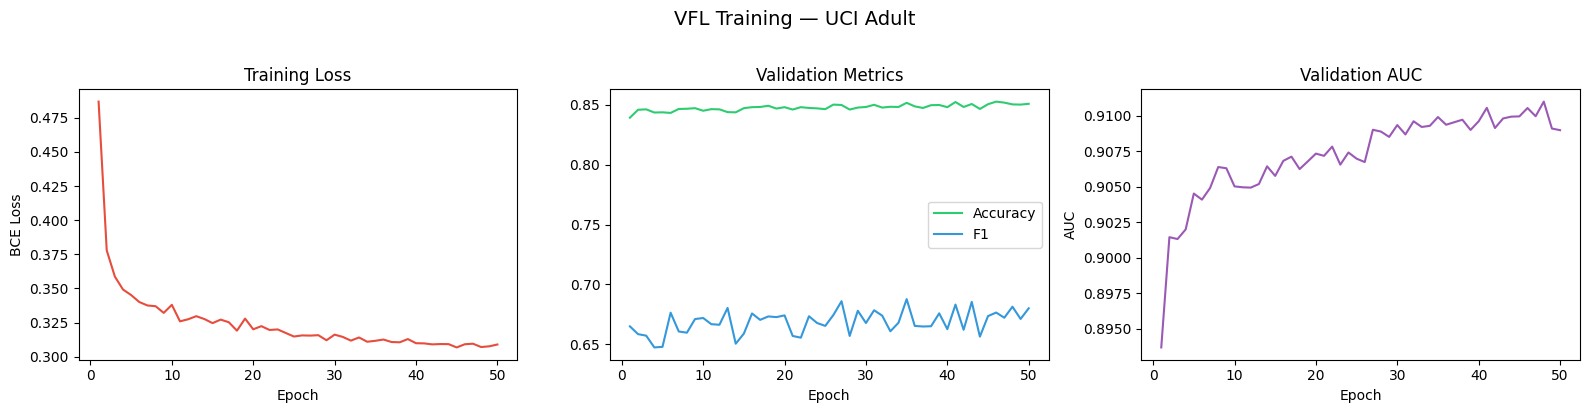

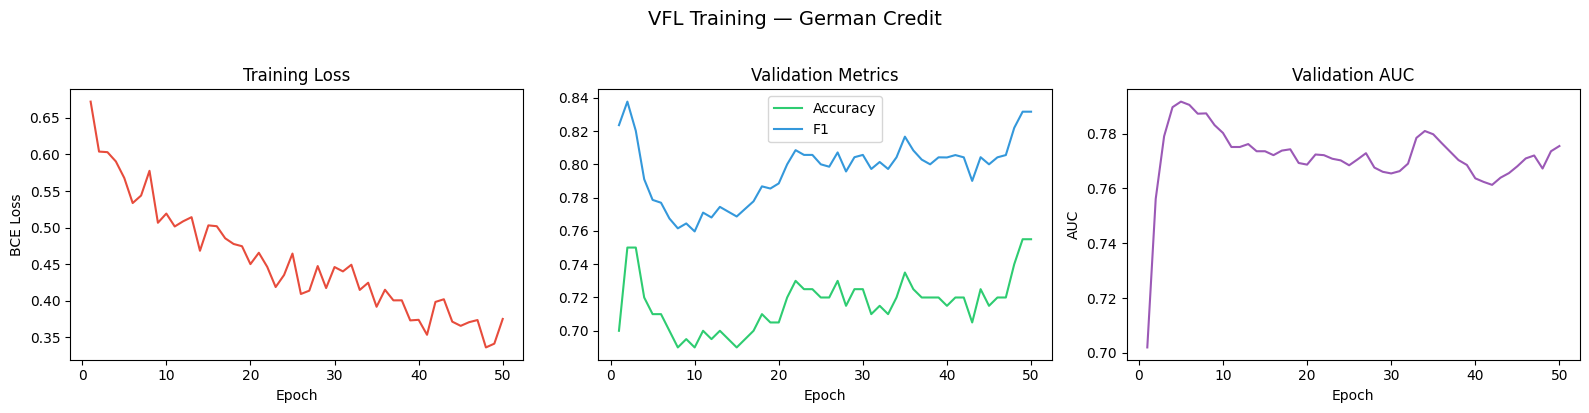

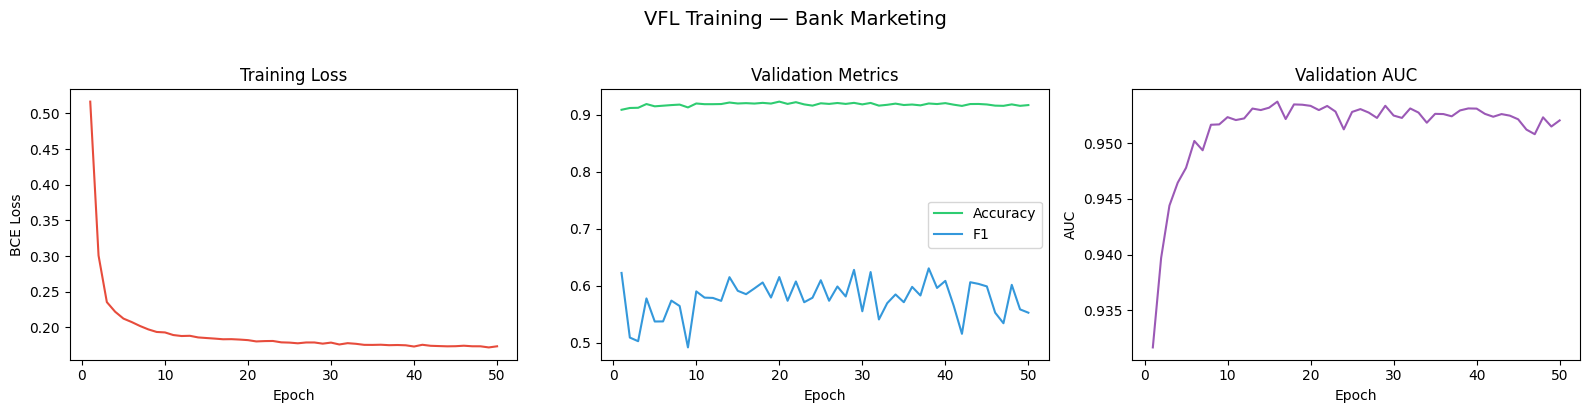

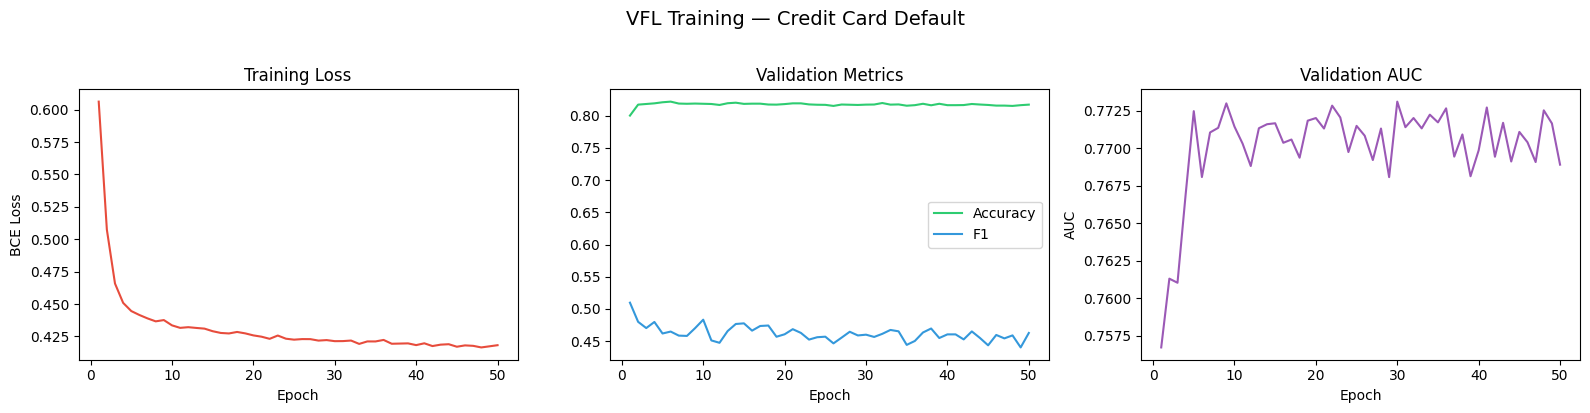

In [ ]:
def plot_training_curves(hist, title):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    epochs = range(1, len(hist['loss']) + 1)

    axes[0].plot(epochs, hist['loss'], color='#e74c3c')
    axes[0].set_title('Training Loss'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('BCE Loss')

    axes[1].plot(epochs, hist['acc'], label='Accuracy', color='#2ecc71')
    axes[1].plot(epochs, hist['f1'],  label='F1',       color='#3498db')
    axes[1].set_title('Validation Metrics'); axes[1].set_xlabel('Epoch')
    axes[1].legend()

    axes[2].plot(epochs, hist['auc'], color='#9b59b6')
    axes[2].set_title('Validation AUC'); axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('AUC')

    fig.suptitle(title, fontsize=14, y=1.02)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{title.replace(' ','_').replace('—','')}.png", dpi=150, bbox_inches='tight')
    plt.show()

plot_training_curves(hist_adult,  'VFL Training — UCI Adult')
plot_training_curves(hist_german, 'VFL Training — German Credit')
plot_training_curves(hist_bank,   'VFL Training — Bank Marketing')
plot_training_curves(hist_credit, 'VFL Training — Credit Card Default')

### 9.4 Unlearning Method Comparison — Bar Charts

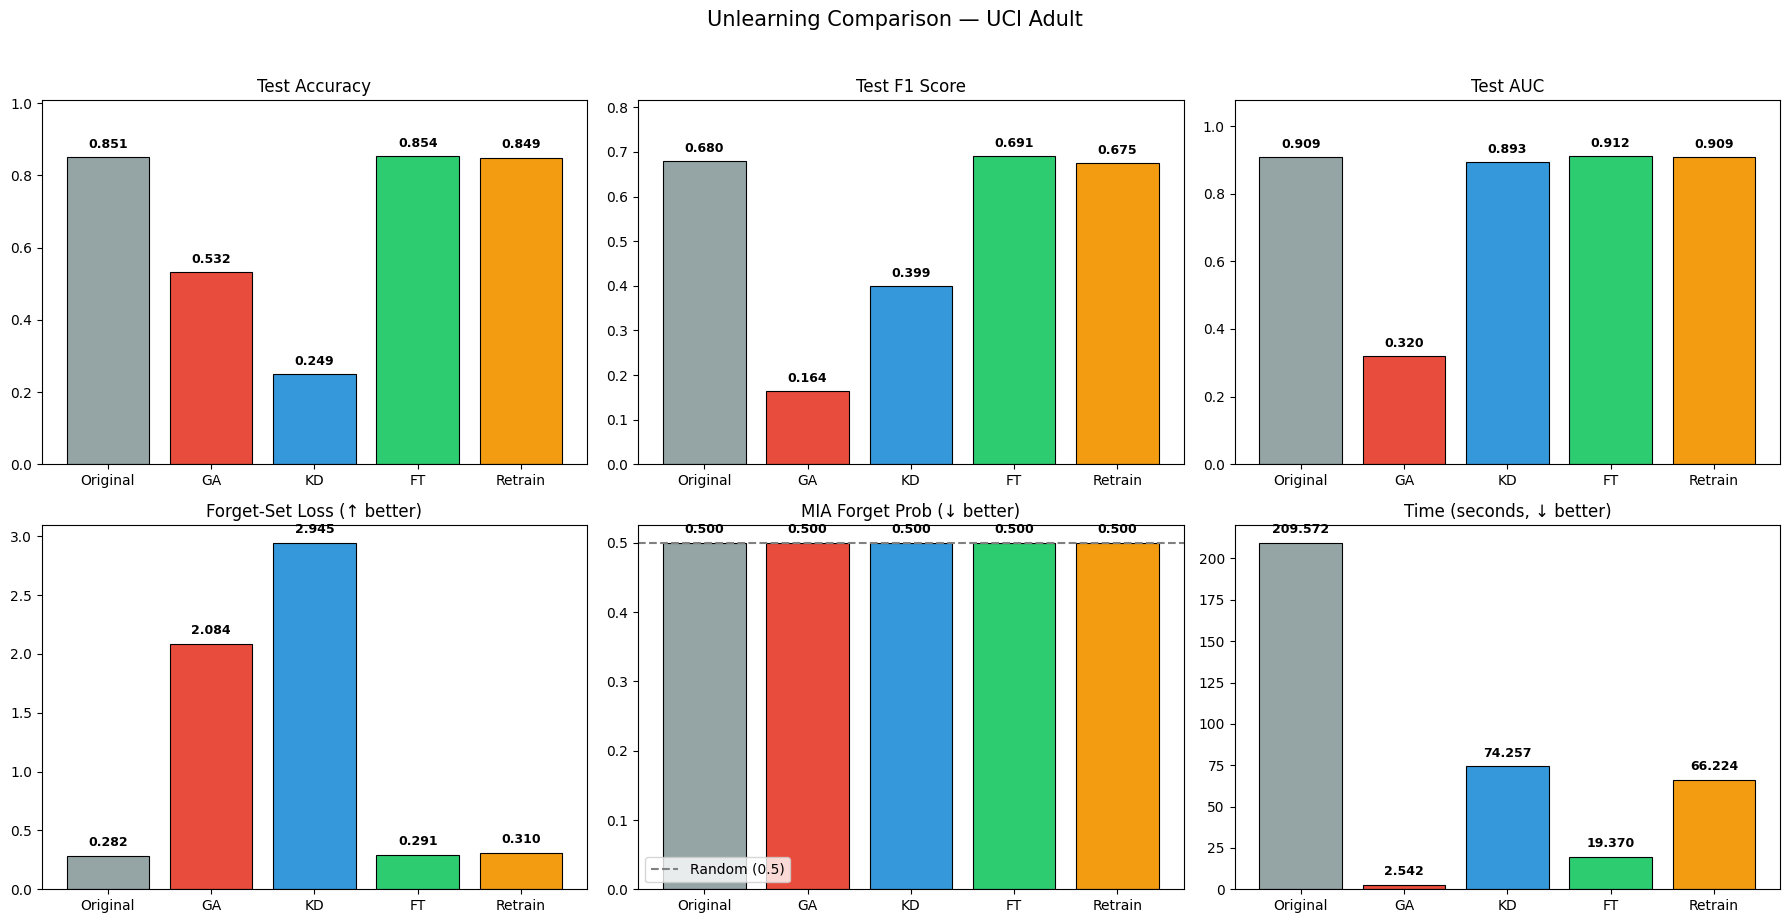

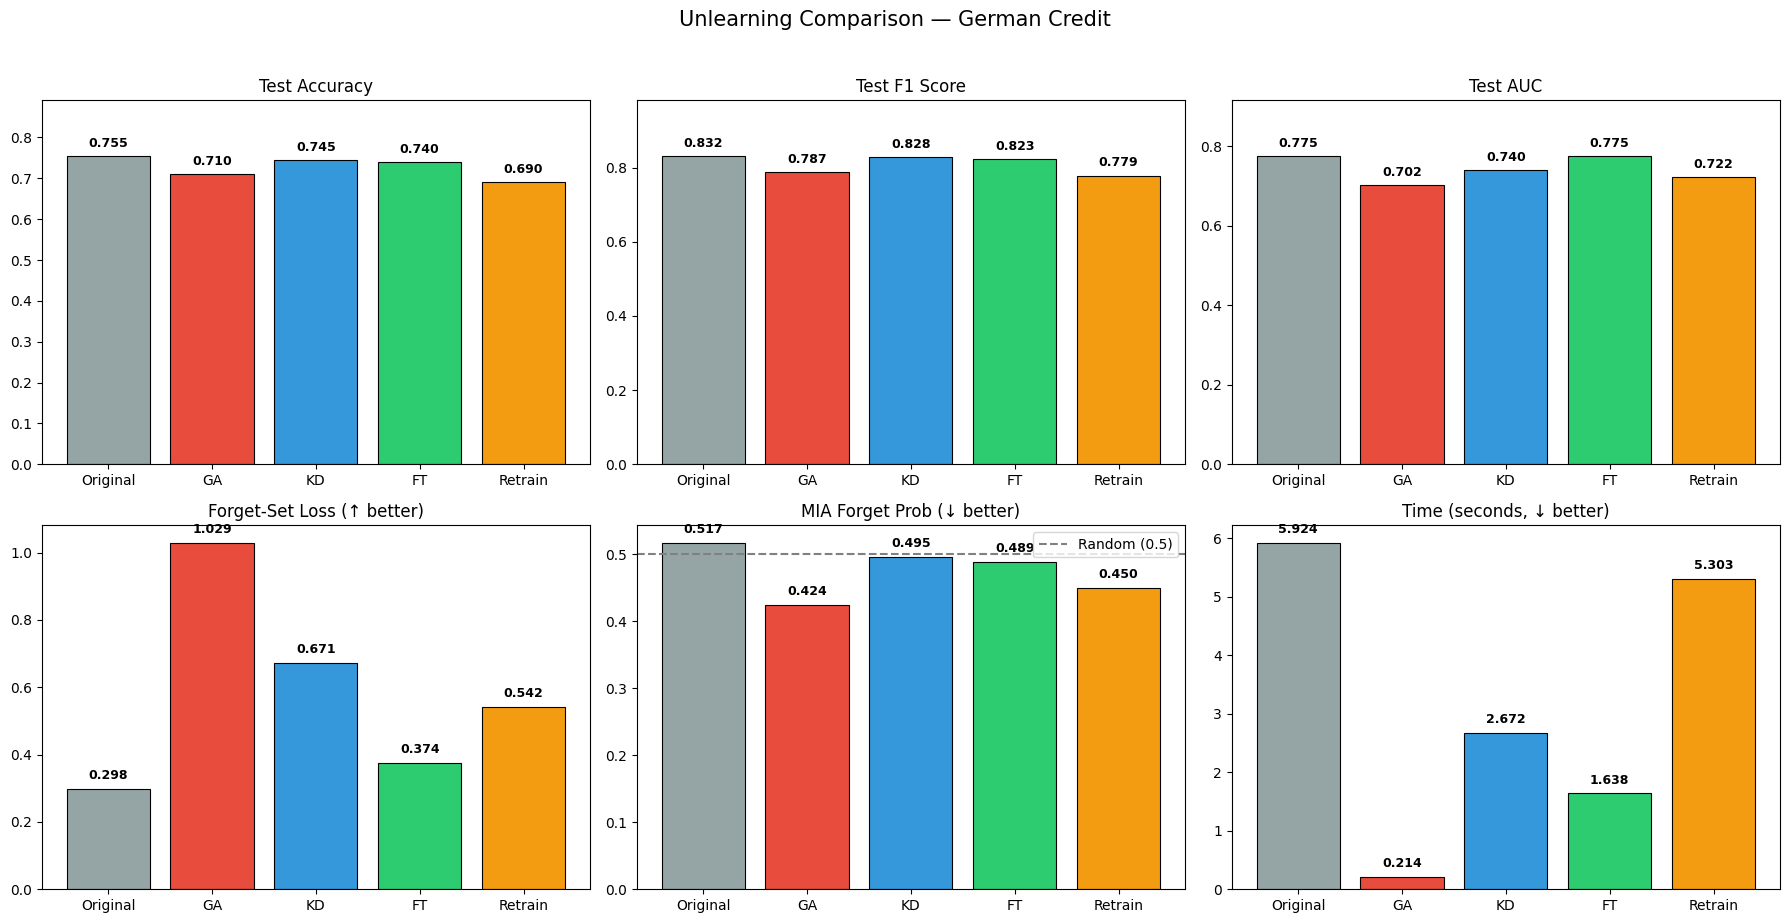

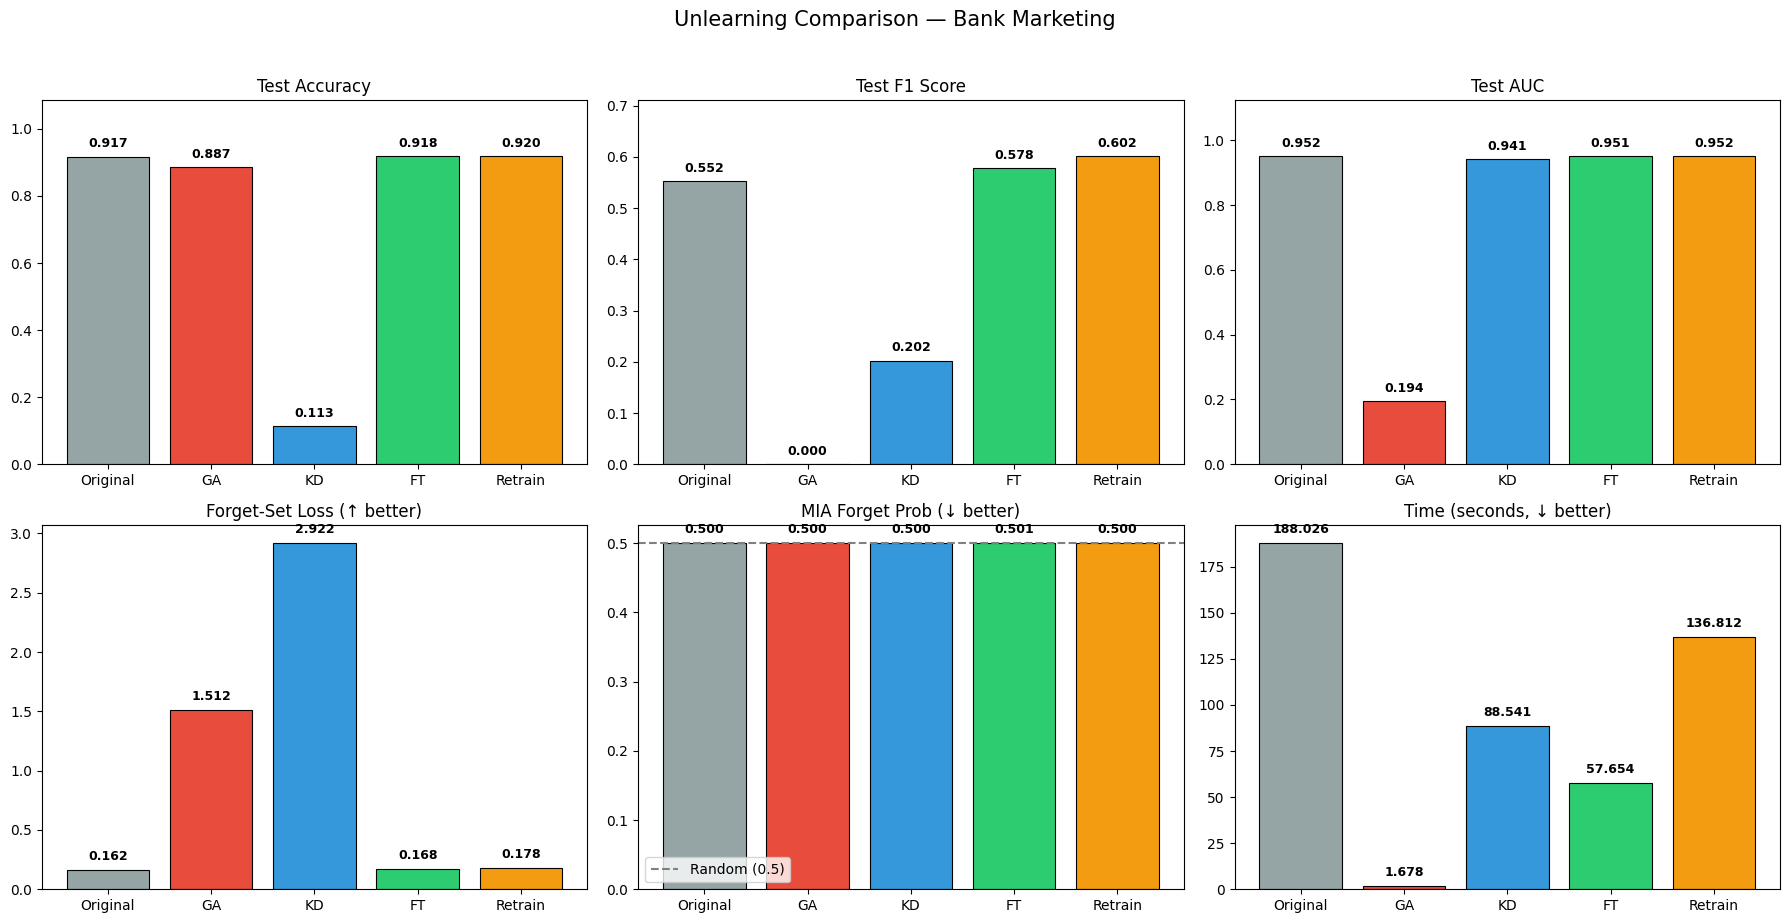

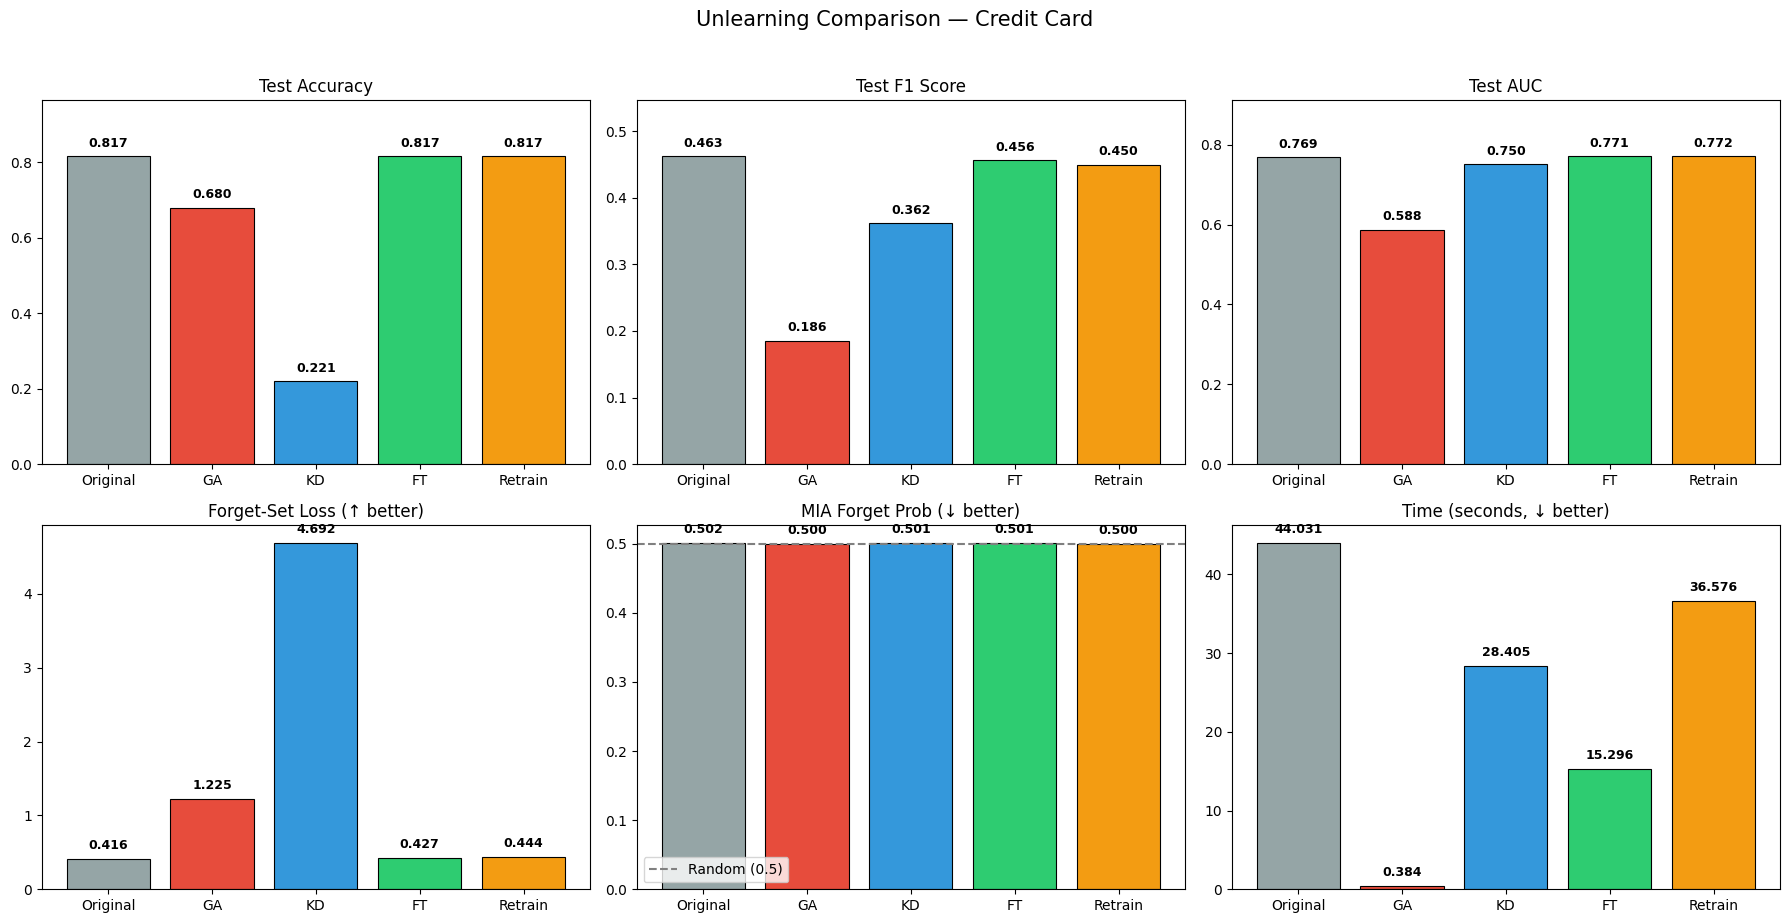

In [ ]:
def plot_comparison_bars(results, dataset_name):
    methods = ['original', 'Gradient Ascent', 'Knowledge Distillation', 'Fine-Tuning', 'Retrain (gold)']
    labels  = ['Original', 'GA', 'KD', 'FT', 'Retrain']
    colors  = ['#95a5a6', '#e74c3c', '#3498db', '#2ecc71', '#f39c12']

    fig, axes = plt.subplots(2, 3, figsize=(18, 9))

    metrics_top = [('accuracy', 'Test Accuracy'), ('f1', 'Test F1 Score'), ('auc', 'Test AUC')]
    metrics_bot = [('forget_loss', 'Forget-Set Loss (↑ better)'),
                   ('mia_forget_prob', 'MIA Forget Prob (↓ better)'),
                   ('time_s', 'Time (seconds, ↓ better)')]

    for ax, (key, title) in zip(axes[0], metrics_top):
        vals = [results[m][key] for m in methods]
        bars = ax.bar(labels, vals, color=colors, edgecolor='black', linewidth=0.8)
        ax.set_title(title, fontsize=12)
        ax.set_ylim(0, max(vals) * 1.18)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width()/2, b.get_height() + max(vals)*0.02,
                    f'{v:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

    for ax, (key, title) in zip(axes[1], metrics_bot):
        vals = [results[m][key] for m in methods]
        bars = ax.bar(labels, vals, color=colors, edgecolor='black', linewidth=0.8)
        ax.set_title(title, fontsize=12)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width()/2, b.get_height() + max(vals)*0.02,
                    f'{v:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

    axes[1][1].axhline(0.5, ls='--', color='gray', label='Random (0.5)')
    axes[1][1].legend()

    fig.suptitle(f'Unlearning Comparison — {dataset_name}', fontsize=15, y=1.02)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/Unlearning_Comparison_{dataset_name.replace(' ','_')}.png",
                dpi=150, bbox_inches='tight')
    plt.show()

for ds_name, res in [('UCI Adult', results_adult), ('German Credit', results_german),
                      ('Bank Marketing', results_bank), ('Credit Card', results_credit)]:
    plot_comparison_bars(res, ds_name)

### 9.5 Radar / Spider Chart — Multi-Metric View

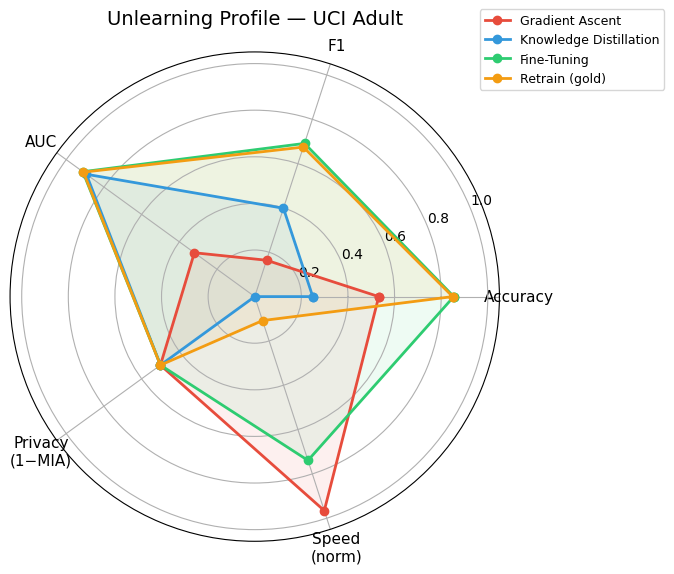

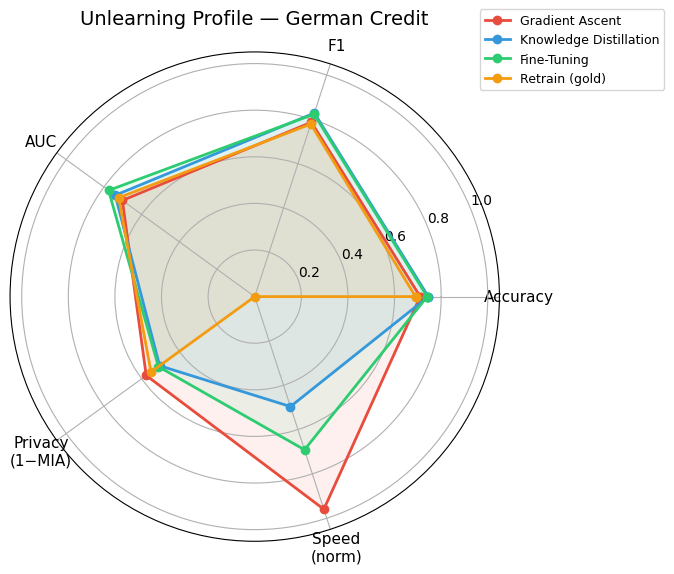

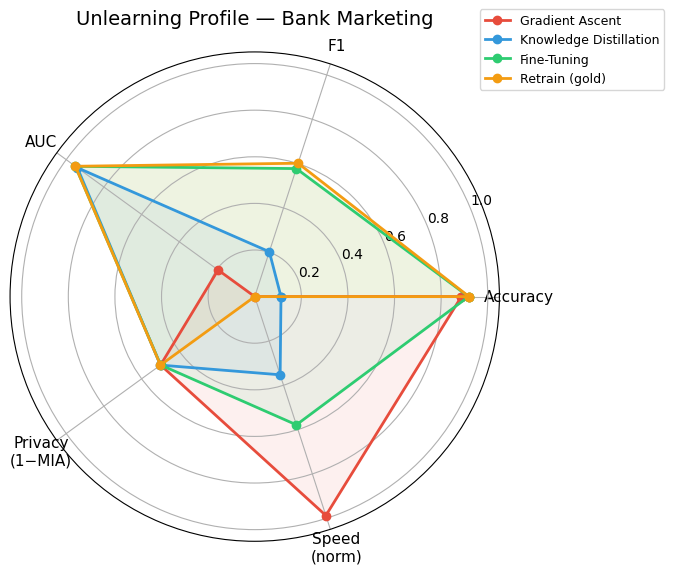

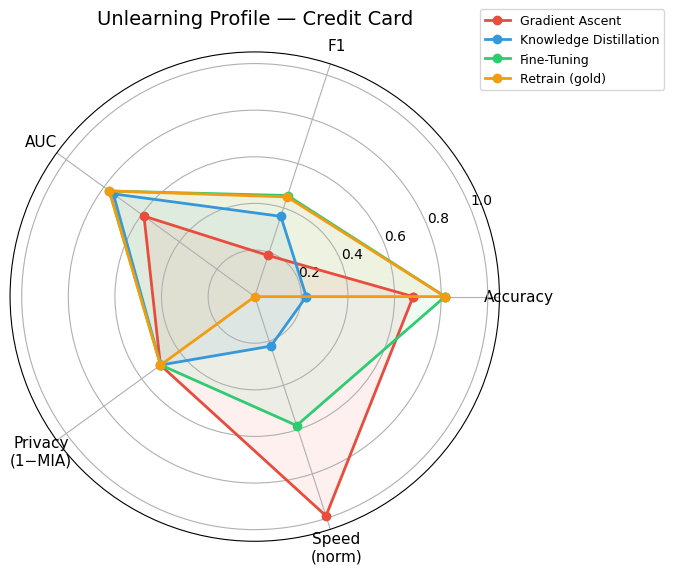

In [ ]:
def plot_radar(results, dataset_name):
    """Radar chart: Accuracy, F1, AUC, 1-MIA_prob (privacy), normalised speed."""
    methods = ['Gradient Ascent', 'Knowledge Distillation', 'Fine-Tuning', 'Retrain (gold)']
    colors  = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']
    categories = ['Accuracy', 'F1', 'AUC', 'Privacy\n(1−MIA)', 'Speed\n(norm)']

    max_time = max(results[m]['time_s'] for m in methods)

    angles = np.linspace(0, 2 * np.pi, len(categories), endpoint=False).tolist()
    angles += angles[:1]

    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
    for meth, col in zip(methods, colors):
        r = results[meth]
        vals = [
            r['accuracy'],
            r['f1'],
            r['auc'],
            1 - r['mia_forget_prob'],
            1 - r['time_s'] / max(max_time, 1e-9),
        ]
        vals += vals[:1]
        ax.plot(angles, vals, 'o-', label=meth, color=col, linewidth=2)
        ax.fill(angles, vals, alpha=0.08, color=col)

    ax.set_thetagrids(np.degrees(angles[:-1]), categories, fontsize=11)
    ax.set_ylim(0, 1.05)
    ax.set_title(f'Unlearning Profile — {dataset_name}', fontsize=14, pad=20)
    ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.1), fontsize=9)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/Radar_{dataset_name.replace(' ','_')}.png", dpi=150, bbox_inches='tight')
    plt.show()

for ds_name, res in [('UCI Adult', results_adult), ('German Credit', results_german),
                      ('Bank Marketing', results_bank), ('Credit Card', results_credit)]:
    plot_radar(res, ds_name)

### 9.6 Heatmap — Cross-Dataset, Cross-Method Comparison

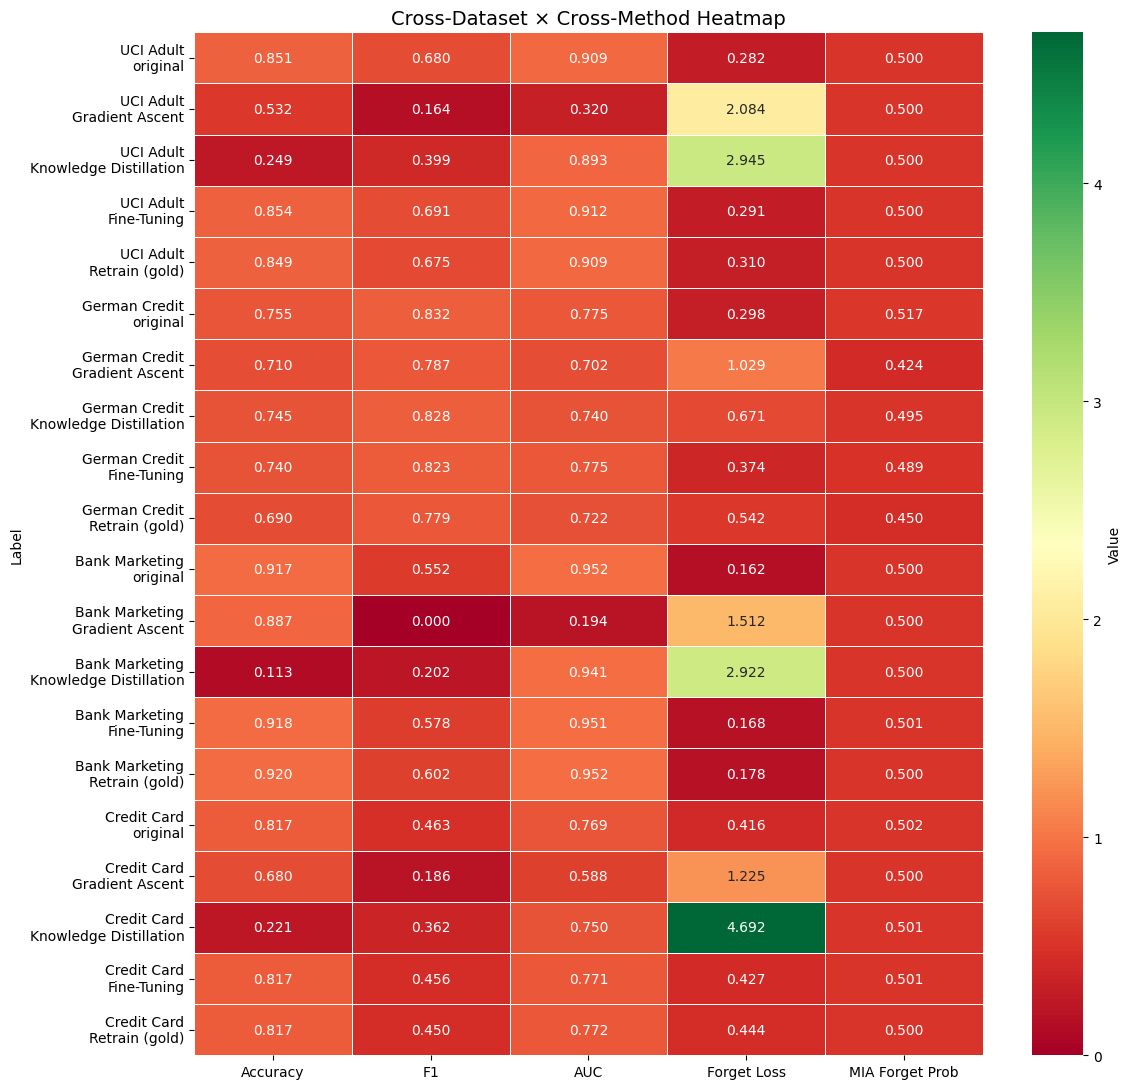

In [ ]:
def plot_heatmap(df_all):
    pivot_metrics = ['Accuracy', 'F1', 'AUC', 'Forget Loss', 'MIA Forget Prob']
    df_sub = df_all[['Dataset', 'Method'] + pivot_metrics].copy()
    df_sub['Label'] = df_sub['Dataset'] + '\n' + df_sub['Method']
    df_sub = df_sub.set_index('Label')[pivot_metrics]

    fig, ax = plt.subplots(figsize=(12, len(df_sub) * 0.5 + 1))
    sns.heatmap(df_sub, annot=True, fmt='.3f', cmap='RdYlGn', linewidths=0.5,
                ax=ax, cbar_kws={'label': 'Value'})
    ax.set_title('Cross-Dataset × Cross-Method Heatmap', fontsize=14)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/Heatmap_Cross_Dataset.png", dpi=150, bbox_inches='tight')
    plt.show()

plot_heatmap(df_all)

### 9.7 Privacy–Utility Trade-off Scatter

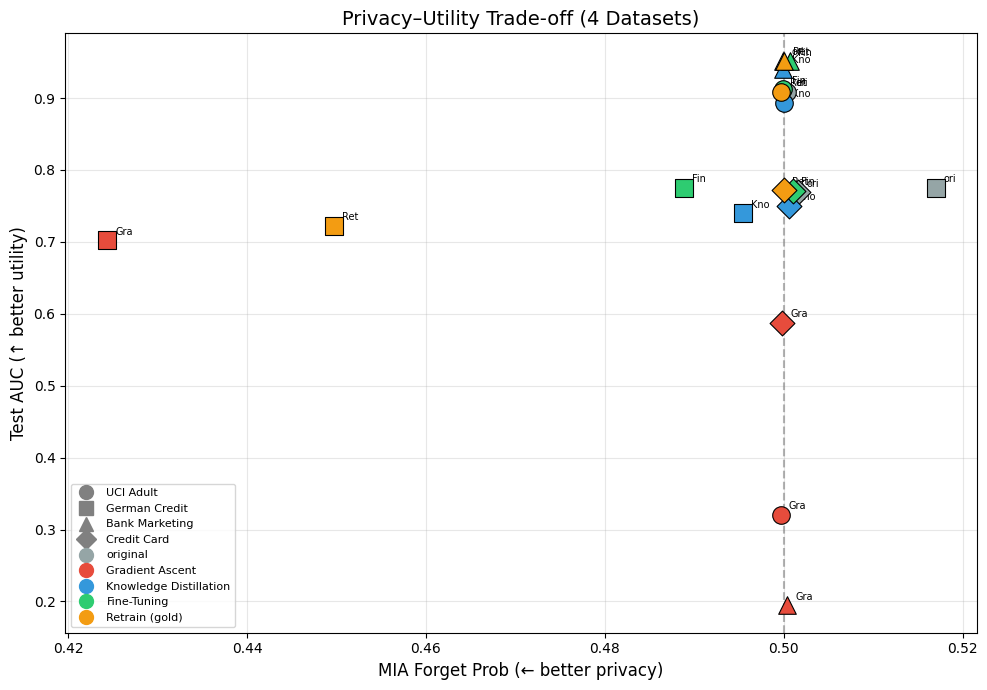

In [ ]:
def plot_privacy_utility(df_all):
    """X = MIA forget prob (lower = better privacy), Y = Test AUC (higher = better utility)."""
    markers = {'UCI Adult': 'o', 'German Credit': 's', 'Bank Marketing': '^', 'Credit Card': 'D'}
    colors  = {'original': '#95a5a6', 'Gradient Ascent': '#e74c3c',
               'Knowledge Distillation': '#3498db', 'Fine-Tuning': '#2ecc71',
               'Retrain (gold)': '#f39c12'}

    fig, ax = plt.subplots(figsize=(10, 7))
    for _, row in df_all.iterrows():
        ax.scatter(row['MIA Forget Prob'], row['AUC'],
                   marker=markers[row['Dataset']], color=colors[row['Method']],
                   s=160, edgecolors='black', linewidth=0.8, zorder=5)
        ax.annotate(row['Method'][:3], (row['MIA Forget Prob'], row['AUC']),
                    textcoords='offset points', xytext=(6, 4), fontsize=7)

    ax.axvline(0.5, ls='--', color='gray', alpha=0.6, label='Random MIA (0.5)')
    ax.set_xlabel('MIA Forget Prob (← better privacy)', fontsize=12)
    ax.set_ylabel('Test AUC (↑ better utility)', fontsize=12)
    ax.set_title('Privacy–Utility Trade-off (4 Datasets)', fontsize=14)

    from matplotlib.lines import Line2D
    h = [Line2D([0],[0], marker=v, color='gray', ls='', ms=10, label=k)
         for k,v in markers.items()]
    h += [Line2D([0],[0], marker='o', color=c, ls='', ms=10, label=k)
          for k,c in colors.items()]
    ax.legend(handles=h, fontsize=8, loc='lower left')
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/Privacy_Utility_Tradeoff.png", dpi=150, bbox_inches='tight')
    plt.show()

plot_privacy_utility(df_all)

### 9.8 Timing Comparison

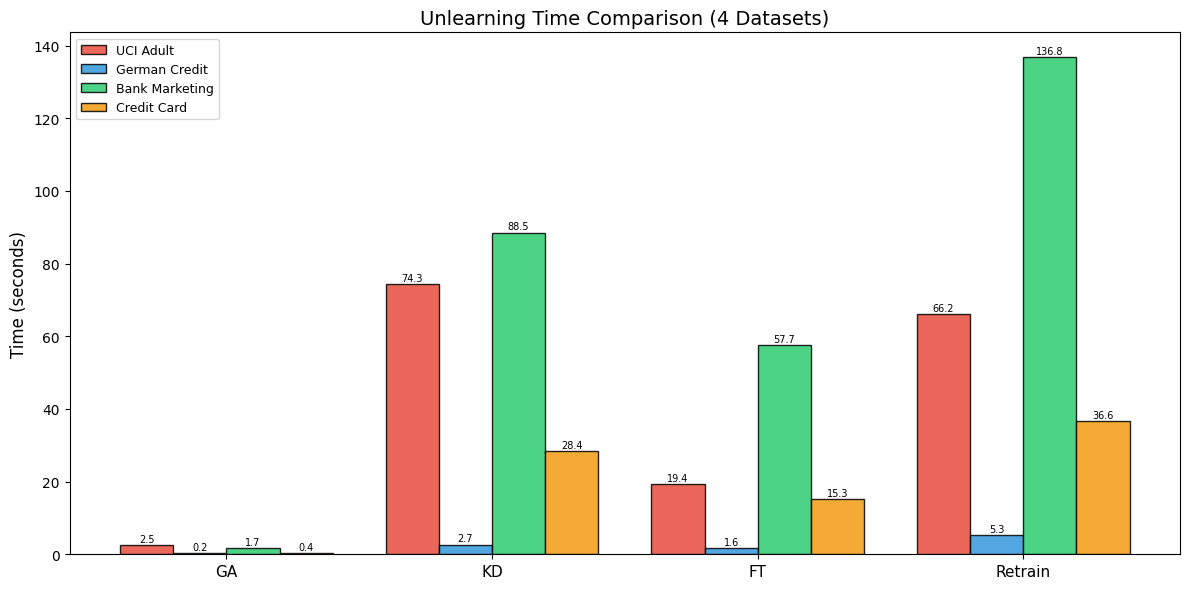

In [ ]:
def plot_timing(all_results):
    methods = ['Gradient Ascent', 'Knowledge Distillation', 'Fine-Tuning', 'Retrain (gold)']
    labels  = ['GA', 'KD', 'FT', 'Retrain']
    ds_names = list(all_results.keys())
    colors_ds = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']

    x = np.arange(len(labels))
    n_ds = len(ds_names)
    w = 0.8 / n_ds

    fig, ax = plt.subplots(figsize=(12, 6))
    for i, ds_name in enumerate(ds_names):
        res = all_results[ds_name]
        times = [res[m]['time_s'] for m in methods]
        bars = ax.bar(x + i * w - (n_ds - 1) * w / 2, times, w,
                      label=ds_name, color=colors_ds[i], edgecolor='black', alpha=0.85)
        for b in bars:
            ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.3,
                    f'{b.get_height():.1f}', ha='center', va='bottom', fontsize=7)

    ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=11)
    ax.set_ylabel('Time (seconds)', fontsize=12)
    ax.set_title('Unlearning Time Comparison (4 Datasets)', fontsize=14)
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/Timing_Comparison.png", dpi=150, bbox_inches='tight')
    plt.show()

plot_timing({
    'UCI Adult': results_adult,
    'German Credit': results_german,
    'Bank Marketing': results_bank,
    'Credit Card': results_credit,
})

### 9.9 Forget-Set Loss Distribution (Before vs After Unlearning)

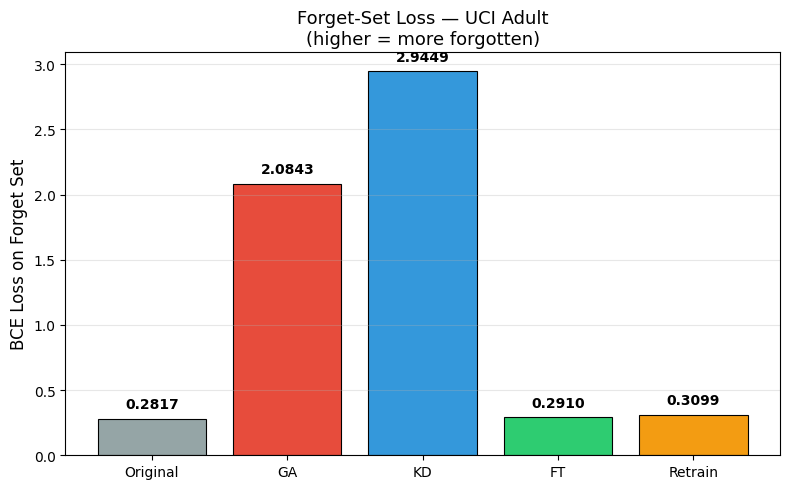

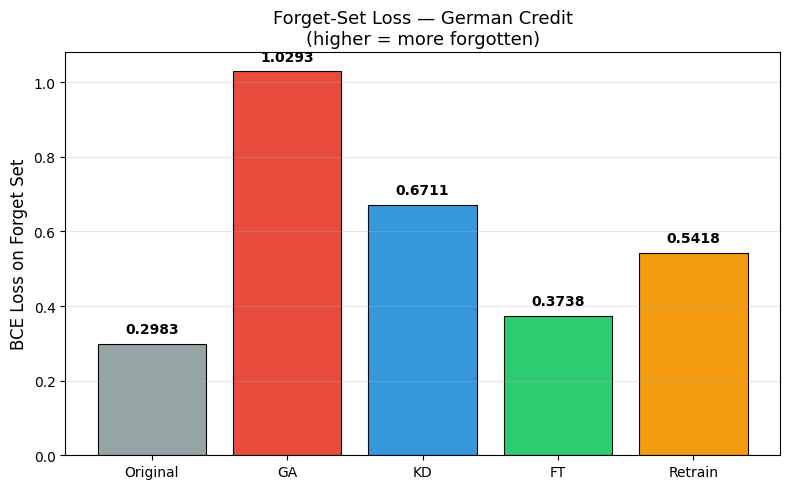

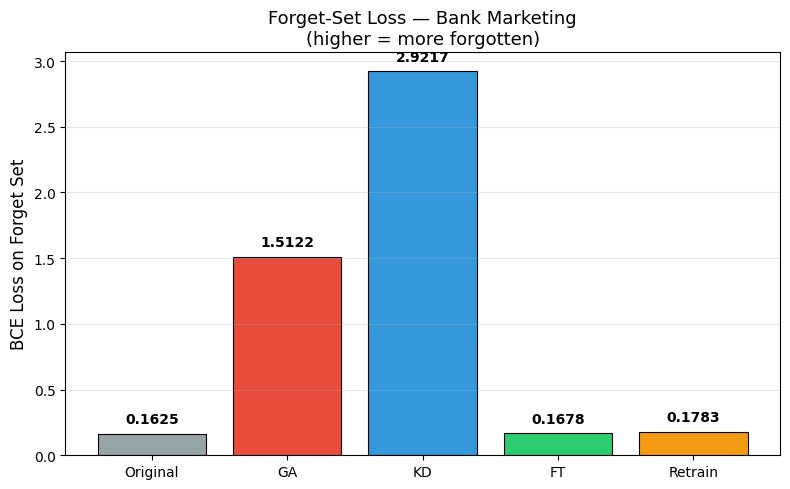

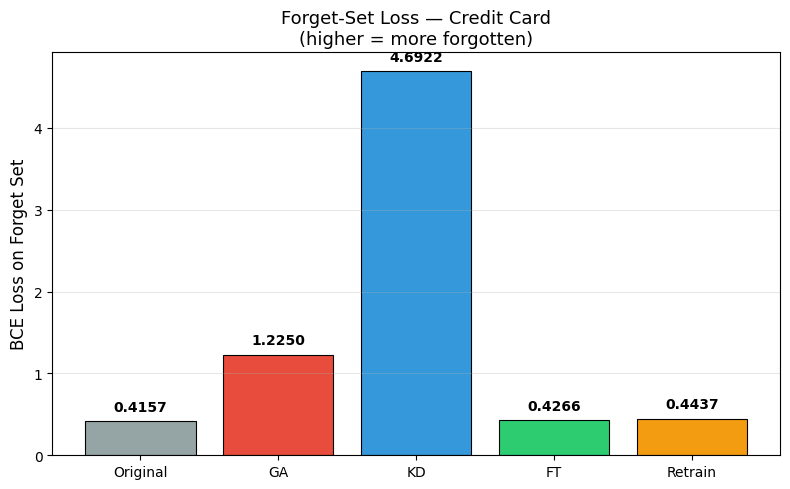

In [ ]:
def plot_forget_loss_comparison(results, dataset_name):
    methods = ['original', 'Gradient Ascent', 'Knowledge Distillation', 'Fine-Tuning', 'Retrain (gold)']
    labels  = ['Original', 'GA', 'KD', 'FT', 'Retrain']
    colors  = ['#95a5a6', '#e74c3c', '#3498db', '#2ecc71', '#f39c12']
    vals    = [results[m]['forget_loss'] for m in methods]

    fig, ax = plt.subplots(figsize=(8, 5))
    bars = ax.bar(labels, vals, color=colors, edgecolor='black', linewidth=0.8)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + max(vals)*0.02,
                f'{v:.4f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.set_ylabel('BCE Loss on Forget Set', fontsize=12)
    ax.set_title(f'Forget-Set Loss — {dataset_name}\n(higher = more forgotten)', fontsize=13)
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/Forget_Loss_{dataset_name.replace(' ','_')}.png",
                dpi=150, bbox_inches='tight')
    plt.show()

for ds_name, res in [('UCI Adult', results_adult), ('German Credit', results_german),
                      ('Bank Marketing', results_bank), ('Credit Card', results_credit)]:
    plot_forget_loss_comparison(res, ds_name)

### 9.10 MIA Membership Probability Distribution

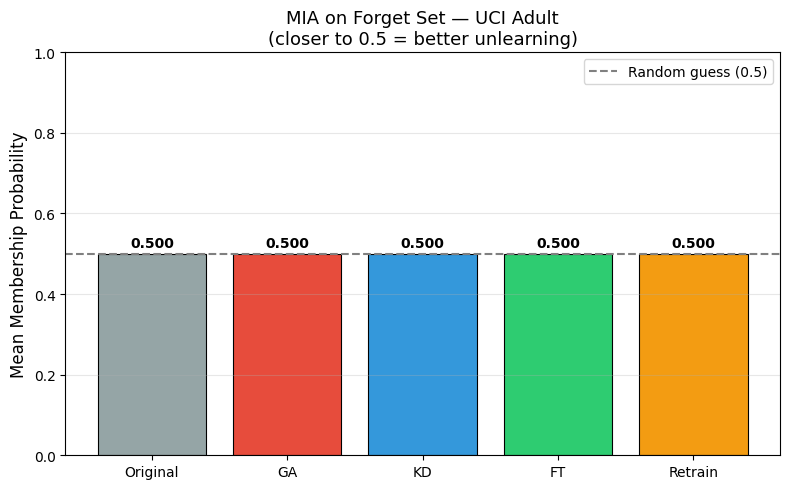

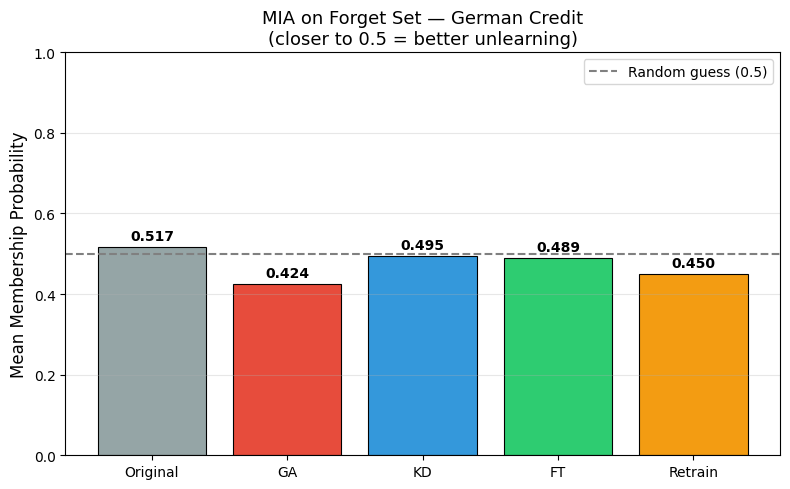

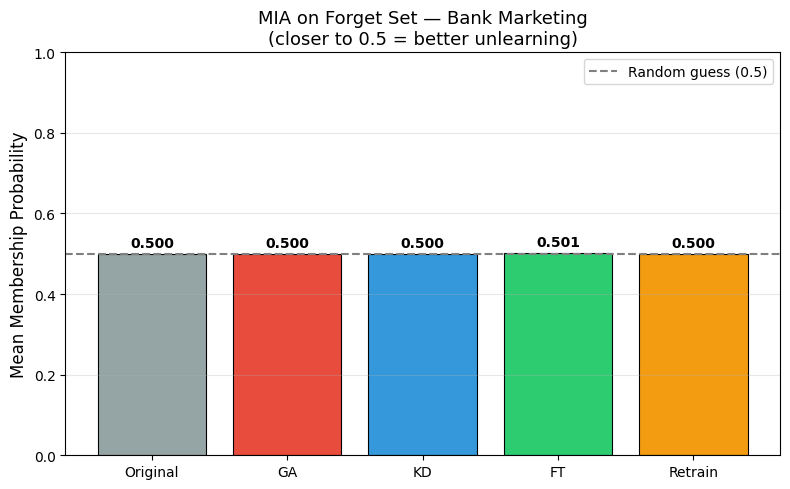

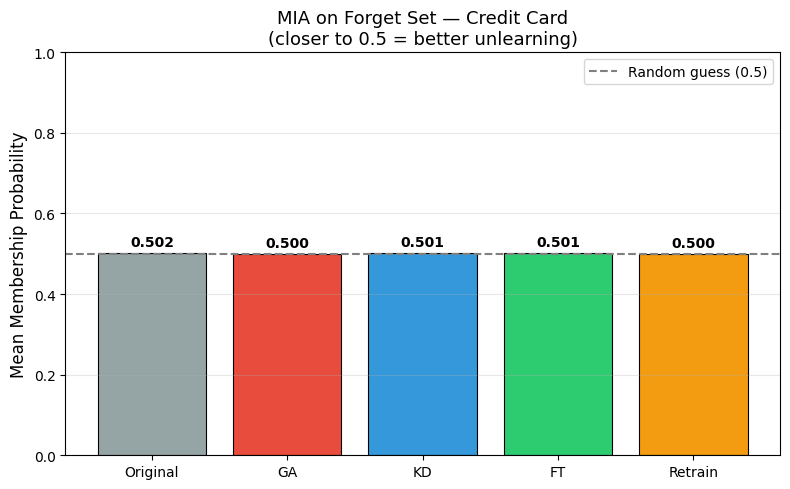

In [ ]:
def plot_mia_comparison(results, dataset_name):
    methods = ['original', 'Gradient Ascent', 'Knowledge Distillation', 'Fine-Tuning', 'Retrain (gold)']
    labels  = ['Original', 'GA', 'KD', 'FT', 'Retrain']
    colors  = ['#95a5a6', '#e74c3c', '#3498db', '#2ecc71', '#f39c12']
    vals    = [results[m]['mia_forget_prob'] for m in methods]

    fig, ax = plt.subplots(figsize=(8, 5))
    bars = ax.bar(labels, vals, color=colors, edgecolor='black', linewidth=0.8)
    ax.axhline(0.5, ls='--', color='gray', label='Random guess (0.5)')
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01,
                f'{v:.3f}', ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.set_ylabel('Mean Membership Probability', fontsize=12)
    ax.set_title(f'MIA on Forget Set — {dataset_name}\n(closer to 0.5 = better unlearning)', fontsize=13)
    ax.set_ylim(0, 1); ax.legend(fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/MIA_Forget_{dataset_name.replace(' ','_')}.png",
                dpi=150, bbox_inches='tight')
    plt.show()

for ds_name, res in [('UCI Adult', results_adult), ('German Credit', results_german),
                      ('Bank Marketing', results_bank), ('Credit Card', results_credit)]:
    plot_mia_comparison(res, ds_name)

### 9.11 Three Verification Attacks — Side-by-Side Comparison

| Attack | Signal Source | Attack Classifier | Key Metric |
|--------|--------------|-------------------|------------|
| **Output MIA** | Output logits / confidence | Logistic Regression | Forget-set membership prob |
| **Gradient MIA** | Per-sample gradient norms & statistics | Random Forest | Forget-set membership prob |
| **FUMA** | Before-vs-after prediction & gradient *divergence* | Gradient Boosting | Detection rate (lower = better) |

Successful unlearning should push all membership probabilities toward **0.5** and FUMA detection rate toward **0**.

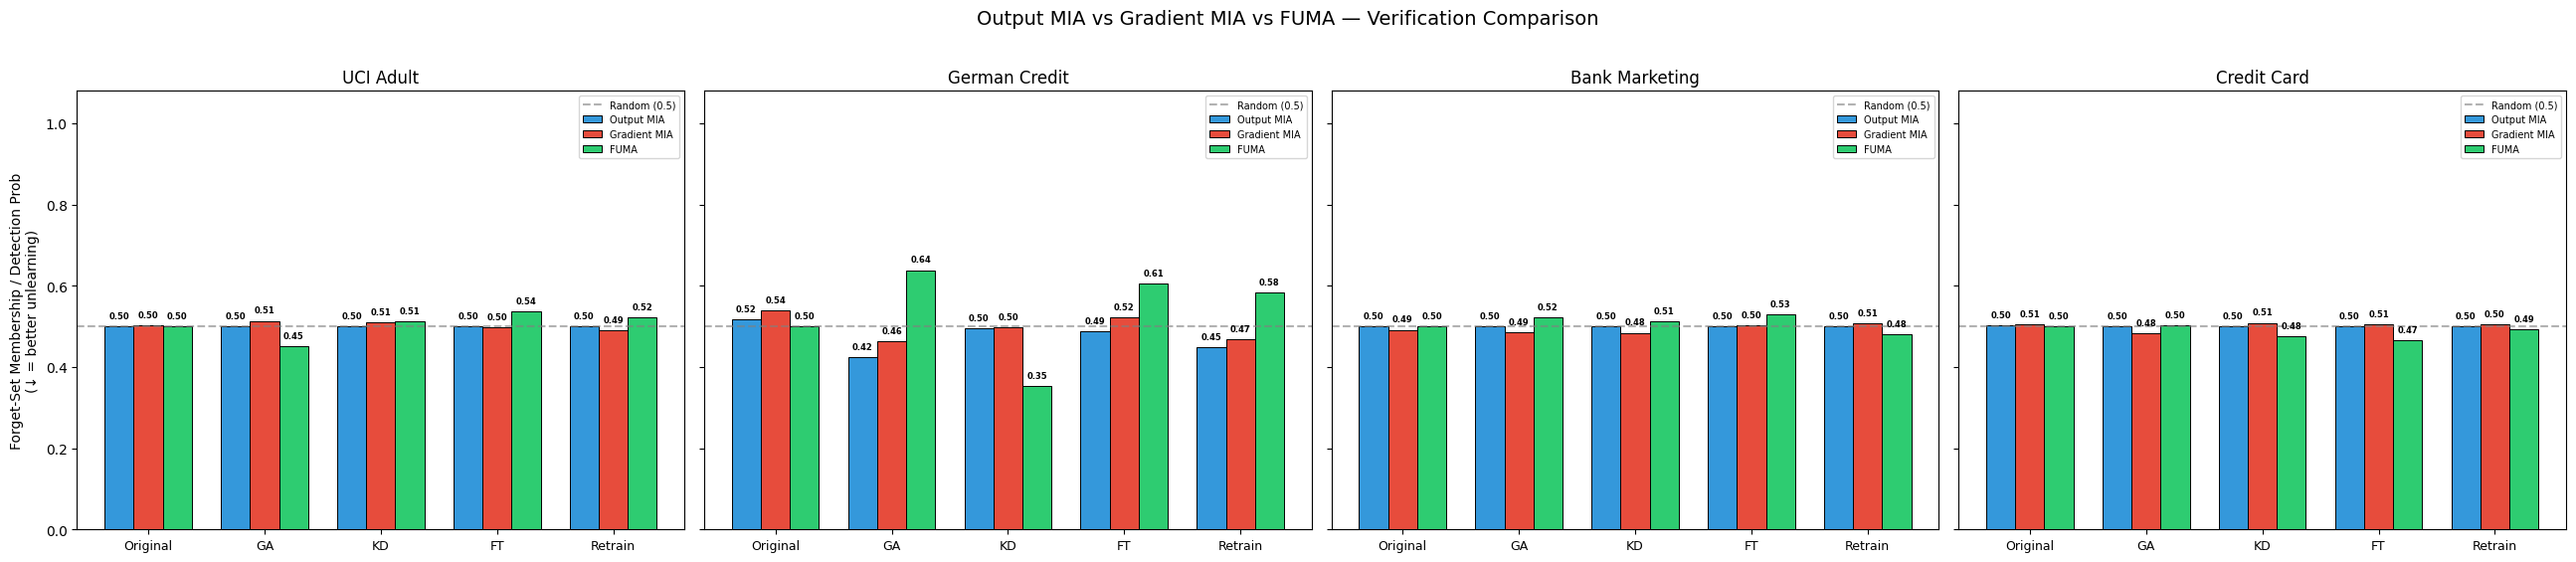

In [ ]:
def plot_three_attacks_bars(all_results):
    """Grouped bar chart: Output-MIA vs Gradient-MIA vs FUMA
    for each unlearning method, across all datasets."""
    methods = ['original', 'Gradient Ascent', 'Knowledge Distillation', 'Fine-Tuning', 'Retrain (gold)']
    labels  = ['Original', 'GA', 'KD', 'FT', 'Retrain']
    ds_names = list(all_results.keys())

    fig, axes = plt.subplots(1, len(ds_names), figsize=(6.5 * len(ds_names), 5.5), sharey=True)
    if len(ds_names) == 1:
        axes = [axes]

    for ax, ds_name in zip(axes, ds_names):
        res = all_results[ds_name]
        mia_vals  = [res[m]['mia_forget_prob'] for m in methods]
        gmia_vals = [res[m].get('gmia_forget_prob', np.nan) for m in methods]
        fuma_vals = [res[m].get('fuma_forget_prob', np.nan) for m in methods]

        x = np.arange(len(labels))
        w = 0.25
        b1 = ax.bar(x - w,   mia_vals,  w, label='Output MIA',   color='#3498db', edgecolor='black', linewidth=0.7)
        b2 = ax.bar(x,        gmia_vals, w, label='Gradient MIA', color='#e74c3c', edgecolor='black', linewidth=0.7)
        b3 = ax.bar(x + w,    fuma_vals, w, label='FUMA',          color='#2ecc71', edgecolor='black', linewidth=0.7)

        ax.axhline(0.5, ls='--', color='gray', alpha=0.6, label='Random (0.5)')
        ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9)
        ax.set_title(ds_name, fontsize=12)
        ax.set_ylim(0, 1.08)
        ax.legend(fontsize=7, loc='upper right')
        for bars in [b1, b2, b3]:
            for b in bars:
                h = b.get_height()
                if not np.isnan(h):
                    ax.text(b.get_x() + b.get_width()/2, h + 0.015,
                            f'{h:.2f}', ha='center', va='bottom', fontsize=6, fontweight='bold')

    axes[0].set_ylabel('Forget-Set Membership / Detection Prob\n(↓ = better unlearning)', fontsize=10)
    fig.suptitle('Output MIA vs Gradient MIA vs FUMA — Verification Comparison', fontsize=14, y=1.02)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/Three_Attacks_Comparison.png", dpi=150, bbox_inches='tight')
    plt.show()

plot_three_attacks_bars({
    'UCI Adult': results_adult,
    'German Credit': results_german,
    'Bank Marketing': results_bank,
    'Credit Card': results_credit,
})

### 9.12 MIA Comparison Heatmap (Output vs Gradient × Method × Dataset)

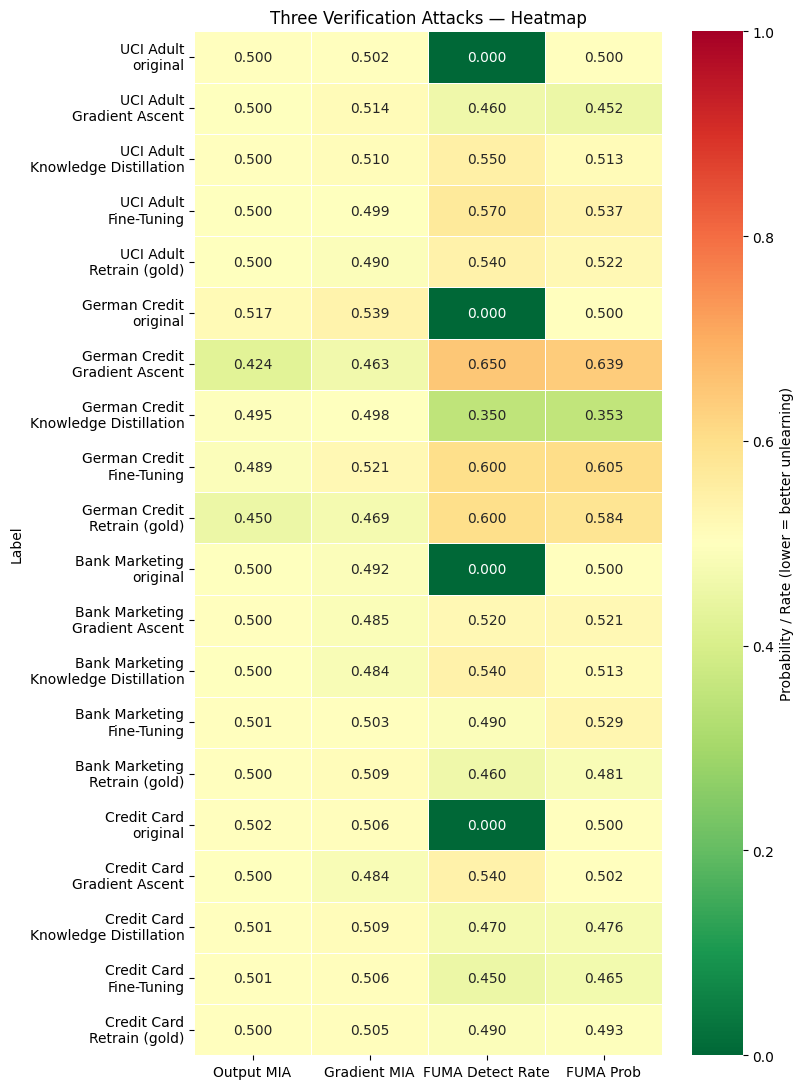

In [ ]:
def plot_verification_heatmap(df_all):
    """Heatmap comparing verification signals across datasets × methods."""
    cols = ['MIA Forget Prob', 'GMIA Forget Prob', 'FUMA Detect Rate', 'FUMA Forget Prob', 'Shadow Prob(full)']
    df_sub = df_all[['Dataset', 'Method'] + cols].copy()
    df_sub['Label'] = df_sub['Dataset'] + '\n' + df_sub['Method']
    df_sub = df_sub.set_index('Label')[cols]
    df_sub.columns = ['Output MIA', 'Gradient MIA', 'FUMA Detect Rate', 'FUMA Prob', 'Shadow P(full)']

    fig, ax = plt.subplots(figsize=(10, len(df_sub) * 0.5 + 1))
    sns.heatmap(df_sub, annot=True, fmt='.3f', cmap='RdYlGn_r', linewidths=0.5,
                vmin=0, vmax=1, ax=ax,
                cbar_kws={'label': 'Probability / Rate (lower = better unlearning)'})
    ax.set_title('Verification Attacks — Heatmap (lower is better)', fontsize=12)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/Verification_Heatmap.png", dpi=150, bbox_inches='tight')
    plt.show()

plot_verification_heatmap(df_all)

### 9.13 MIA Effectiveness Gap — How Much More Does Gradient-MIA Reveal?

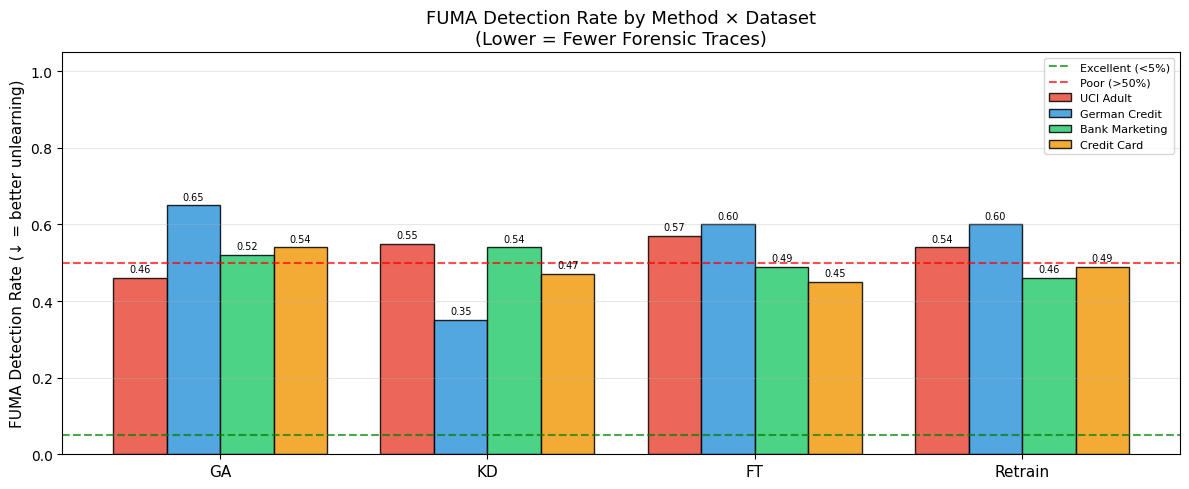


  THREE VERIFICATION ATTACKS — DETAILED COMPARISON

  Dataset          Method                      Output MIA   Grad MIA  FUMA Rate  FUMA Prob    Strictest
  ----------------------------------------------------------------------------------------------------
  UCI Adult        original                        0.5004     0.5021     0.0000     0.5000         GMIA
  UCI Adult        Gradient Ascent                 0.4997     0.5136     0.4600     0.4519         GMIA
  UCI Adult        Knowledge Distillation          0.5000     0.5104     0.5500     0.5126         FUMA
  UCI Adult        Fine-Tuning                     0.5000     0.4988     0.5700     0.5374         FUMA
  UCI Adult        Retrain (gold)                  0.4997     0.4897     0.5400     0.5221         FUMA
  German Credit    original                        0.5170     0.5388     0.0000     0.5000         GMIA
  German Credit    Gradient Ascent                 0.4243     0.4628     0.6500     0.6385         FUMA
  German Cre

In [ ]:
def plot_fuma_detection_rate(all_results):
    """Bar chart showing FUMA detection rate per method × dataset."""
    methods = ['Gradient Ascent', 'Knowledge Distillation', 'Fine-Tuning', 'Retrain (gold)']
    labels  = ['GA', 'KD', 'FT', 'Retrain']
    ds_names = list(all_results.keys())
    colors_ds = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']

    x = np.arange(len(labels))
    n_ds = len(ds_names)
    w = 0.8 / n_ds

    fig, ax = plt.subplots(figsize=(12, 5))
    for i, ds_name in enumerate(ds_names):
        res = all_results[ds_name]
        rates = [res[m].get('fuma_detect_rate', np.nan) for m in methods]
        bars = ax.bar(x + i * w - (n_ds - 1) * w / 2, rates, w,
                      label=ds_name, color=colors_ds[i], edgecolor='black', alpha=0.85)
        for b in bars:
            h = b.get_height()
            if not np.isnan(h):
                ax.text(b.get_x() + b.get_width()/2, h + 0.01,
                        f'{h:.2f}', ha='center', va='bottom', fontsize=7)

    ax.axhline(0.05, ls='--', color='green', alpha=0.7, label='Excellent (<5%)')
    ax.axhline(0.50, ls='--', color='red', alpha=0.7, label='Poor (>50%)')
    ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=11)
    ax.set_ylabel('FUMA Detection Rate (↓ = better unlearning)', fontsize=11)
    ax.set_title('FUMA Detection Rate by Method × Dataset\n(Lower = Fewer Forensic Traces)', fontsize=13)
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=8)
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/FUMA_Detection_Rate.png", dpi=150, bbox_inches='tight')
    plt.show()

all_res_dict = {
    'UCI Adult': results_adult, 'German Credit': results_german,
    'Bank Marketing': results_bank, 'Credit Card': results_credit,
}
plot_fuma_detection_rate(all_res_dict)


# Print comprehensive three-attack comparison table
print("\n" + "=" * 120)
print("  THREE VERIFICATION ATTACKS — DETAILED COMPARISON")
print("=" * 120)
print(f"\n  {'Dataset':<16} {'Method':<26} {'Output MIA':>11} {'Grad MIA':>10} {'FUMA Rate':>10} {'FUMA Prob':>10} {'Strictest':>12}")
print("  " + "-" * 100)
for ds_name, res in all_res_dict.items():
    for meth in ['original', 'Gradient Ascent', 'Knowledge Distillation', 'Fine-Tuning', 'Retrain (gold)']:
        r = res[meth]
        omia = r['mia_forget_prob']
        gmia = r.get('gmia_forget_prob', np.nan)
        fdr  = r.get('fuma_detect_rate', np.nan)
        fpr  = r.get('fuma_forget_prob', np.nan)
        # determine which attack is "strictest" (detects most leakage)
        vals = {'OMIA': omia, 'GMIA': gmia, 'FUMA': fpr}
        vals = {k: v for k, v in vals.items() if not np.isnan(v)}
        strictest = max(vals, key=vals.get) if vals else "N/A"
        print(f"  {ds_name:<16} {meth:<26} {omia:>11.4f} {gmia:>10.4f} {fdr:>10.4f} {fpr:>10.4f} {strictest:>12}")

## 10. Final Summary & Interpretation

In [ ]:
def final_summary(all_results):
    print("=" * 100)
    print("  FINAL SUMMARY — VFL UNLEARNING METHODS (4 DATASETS)")
    print("=" * 100)

    for ds_name, res in all_results.items():
        print(f"\n  {'─'*55}")
        print(f"  Dataset: {ds_name}")
        print(f"  {'─'*55}")
        header = f"  {'Method':<28} {'Acc':>7} {'F1':>7} {'AUC':>7} {'FLoss':>8} {'MIA':>7} {'GMIA':>7} {'FUMA':>7} {'Time':>7}"
        print(header)
        print(f"  {'─'*len(header)}")
        order = ['original', 'Gradient Ascent', 'Knowledge Distillation', 'Fine-Tuning', 'Retrain (gold)']
        for m in order:
            r = res[m]
            gmia = r.get('gmia_forget_prob', float('nan'))
            fdr = r.get('fuma_detect_rate', float('nan'))
            print(f"  {m:<28} {r['accuracy']:7.4f} {r['f1']:7.4f} {r['auc']:7.4f} "
                  f"{r['forget_loss']:8.4f} {r['mia_forget_prob']:7.4f} {gmia:7.4f} {fdr:7.4f} {r['time_s']:6.1f}s")

    print(f"\n{'='*100}")
    print("  KEY TAKE-AWAYS")
    print("=" * 100)
    print("""
  1. Gradient Ascent (GA)  — Fastest unlearning. Effectively raises forget-set loss
     and pushes MIA probability toward random. May slightly degrade test accuracy
     because gradient ascent on a subset can perturb global weights.

  2. Knowledge Distillation (KD)  — Produces a fresh student model that never saw
     the forget set. Strong privacy guarantee (low MIA), but takes longer because
     the entire student is trained from scratch on the retain set.

  3. Fine-Tuning (FT)  — A balanced middle ground: overwrites forget-set knowledge
     by continuing training on the retain set. Moderate speed, usually preserves
     utility well. MIA drop depends on the number of fine-tuning epochs.

  4. Retrain (gold standard)  — Full retraining without the forget set. Provides
     the theoretical upper bound on unlearning effectiveness but is the slowest.
     All three approximate methods aim to match retrain quality at lower cost.

  5. Cross-Dataset Consistency — Results across all four datasets (Adult, German,
     Bank Marketing, Credit Card) confirm that these patterns hold regardless of
     dataset size, class balance, or feature characteristics.

  6. Gradient-MIA vs Output-MIA — Gradient-based MIA exploits per-sample gradient
     signals (norms, layer-wise norms, sparsity, entropy) which encode deeper
     memorisation patterns than output logits alone. It typically detects more
     residual membership information, serving as a stricter unlearning verifier.

  7. FUMA (Forensic Unlearning Membership Attack) — Compares model behaviour
     *before* and *after* unlearning using prediction divergence, loss change,
     gradient magnitude ratio, and gradient direction change. FUMA detection
     rate indicates how many forget-set samples can be forensically identified
     as "unlearned" — lower is better (<5% = excellent).
""")

    # Aggregate cross-dataset statistics
    print("  CROSS-DATASET AGGREGATE STATISTICS")
    print("  " + "─" * 85)
    methods = ['Gradient Ascent', 'Knowledge Distillation', 'Fine-Tuning', 'Retrain (gold)']
    for meth in methods:
        accs = [res[meth]['accuracy'] for res in all_results.values()]
        f1s  = [res[meth]['f1'] for res in all_results.values()]
        mias = [res[meth]['mia_forget_prob'] for res in all_results.values()]
        gmias = [res[meth].get('gmia_forget_prob', np.nan) for res in all_results.values()]
        fdrs  = [res[meth].get('fuma_detect_rate', np.nan) for res in all_results.values()]
        gmias_c = [g for g in gmias if not np.isnan(g)]
        fdrs_c  = [g for g in fdrs if not np.isnan(g)]
        gmia_s = f"GMIA: {np.mean(gmias_c):.4f}±{np.std(gmias_c):.4f}" if gmias_c else "GMIA: N/A"
        fuma_s = f"FUMA: {np.mean(fdrs_c):.4f}±{np.std(fdrs_c):.4f}" if fdrs_c else "FUMA: N/A"
        print(f"  {meth:<28} Acc: {np.mean(accs):.4f}±{np.std(accs):.4f}  "
              f"MIA: {np.mean(mias):.4f}±{np.std(mias):.4f}  {gmia_s}  {fuma_s}")

    # Three-attack comparison summary
    print(f"\n  {'─'*95}")
    print("  THREE VERIFICATION ATTACKS — AGGREGATE COMPARISON")
    print(f"  {'─'*95}")
    print(f"  {'Method':<28} {'Output MIA':>11} {'Grad MIA':>10} {'FUMA DR':>9} {'Strictest':>12}")
    print(f"  {'─'*75}")
    for meth in methods:
        omia_vals = [res[meth]['mia_forget_prob'] for res in all_results.values()]
        gmia_vals = [res[meth].get('gmia_forget_prob', np.nan) for res in all_results.values()]
        fdr_vals  = [res[meth].get('fuma_detect_rate', np.nan) for res in all_results.values()]
        gmia_c = [g for g in gmia_vals if not np.isnan(g)]
        fdr_c  = [g for g in fdr_vals if not np.isnan(g)]
        om = np.mean(omia_vals)
        gm = np.mean(gmia_c) if gmia_c else np.nan
        fm = np.mean(fdr_c) if fdr_c else np.nan
        candidates = {'OMIA': om}
        if not np.isnan(gm): candidates['GMIA'] = gm
        if not np.isnan(fm): candidates['FUMA'] = fm
        strictest = max(candidates, key=candidates.get)
        print(f"  {meth:<28} {om:>11.4f} {gm:>10.4f} {fm:>9.4f} {strictest:>12}")
    print()

final_summary({
    'UCI Adult': results_adult,
    'German Credit': results_german,
    'Bank Marketing': results_bank,
    'Credit Card': results_credit,
})

  FINAL SUMMARY — VFL UNLEARNING METHODS (4 DATASETS)

  ───────────────────────────────────────────────────────
  Dataset: UCI Adult
  ───────────────────────────────────────────────────────
  Method                           Acc      F1     AUC    FLoss     MIA    GMIA    FUMA    Time
  ───────────────────────────────────────────────────────────────────────────────────────────────
  original                      0.8510  0.6800  0.9090   0.2817  0.5004  0.5021  0.0000  209.6s
  Gradient Ascent               0.5322  0.1641  0.3202   2.0843  0.4997  0.5136  0.4600    2.5s
  Knowledge Distillation        0.2490  0.3987  0.8933   2.9449  0.5000  0.5104  0.5500   74.3s
  Fine-Tuning                   0.8541  0.6912  0.9119   0.2910  0.5000  0.4988  0.5700   19.4s
  Retrain (gold)                0.8495  0.6748  0.9087   0.3099  0.4997  0.4897  0.5400   66.2s

  ───────────────────────────────────────────────────────
  Dataset: German Credit
  ────────────────────────────────────────────────